# Analysis dataset EDA: `analysis_measurement`

Explores the modeling table written by `build_analysis_dataset.py` (one row per pre/post measurement of each eligible dam-station pair; columns and design choices in `docs/warehouse_spec.md`, section 3.11), before modeling:

1. Overview: size, context coverage, per-parameter summary
2. Balance: pre vs post samples, years from removal, sampling months
3. Value distributions
4. Seasonality
5. Before vs after: raw and with the seasonal cycle removed
6. Event study: change by year from removal, downstream vs upstream
7. Dam and watershed covariates
8. Climate vs water quality
9. A first simple model per parameter (preview, not final)

Reads the Parquet file directly (no `warehouse.duckdb` connection), so it never locks out Slurm jobs.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

# Project root: the nearest folder at or above this one with etl/ and config/
# (works from any notebooks/ subfolder).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "etl").is_dir() and (p / "config").is_dir())
sys.path.insert(0, str(ROOT))

from etl.common import wq_rules
from etl.common.config import load_config
from etl.common.warehouse import warehouse_dir

CASE_STUDY = "all_removals"
cfg = load_config(CASE_STUDY, project_root=ROOT)
WAREHOUSE = warehouse_dir(cfg)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

df = pd.read_parquet(WAREHOUSE / "analysis_measurement.parquet")

# One label per parameter x fraction ("phosphorus (Total)", "water_temp").
df["series"] = df["parameter_std"].where(
    df["sample_fraction_std"].isna(),
    df["parameter_std"] + " (" + df["sample_fraction_std"].fillna("") + ")",
)

# Skewed, always-positive parameters are looked at on a log10 scale (y).
# Zeros are floored at 0.001 so the log is defined.
LOG_PARAMETERS = {"turbidity", "specific_conductance", "nitrate", "ammonia",
                  "orthophosphate", "phosphorus", "tds"}
df["log_scale"] = df["parameter_std"].isin(LOG_PARAMETERS)
df["y"] = np.where(df["log_scale"], np.log10(df["result_value_std"].clip(lower=1e-3)),
                   df["result_value_std"])
df["post"] = (df["period"] == "post").astype(int)
df["pair"] = df["AR_ID"] + " | " + df["station_id"]

SERIES = df["series"].value_counts().index.tolist()  # most data first


def y_label(series):
    parameter = series.split(" (")[0]
    unit = wq_rules.STANDARD_UNITS.get(parameter, "")
    return f"log10 {unit}" if parameter in LOG_PARAMETERS else unit


def facet_axes(n, ncols=4, width=4, height=3):
    """A grid of n axes, extra ones hidden."""
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(width * ncols, height * nrows), squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, list(axes.flat)


print("Case study:", cfg.name)
print(f"Rows: {len(df):,}; cols: {len(df.columns)}; dams: {df['AR_ID'].nunique()}; stations: {df['station_id'].nunique()}; "
      f"dam-station pairs: {df['pair'].nunique()}; series: {len(SERIES)}")

df.head()

Case study: all_removals
Rows: 69,747; cols: 64; dams: 54; stations: 87; dam-station pairs: 133; series: 15


,measurement_id,daily_id,AR_ID,station_id,parameter_std,sample_fraction_std,removal_year,side,relationship,network_distance_km,period,years_from_removal,drainage_area_ratio,upstream_in_former_reservoir,exposure_status,assigned_AR_ID,n_other_removals_in_window,n_other_upstream_removals_in_window,other_removals_in_window,sample_date,year,month,season,result_value_std,result_unit_std,...,qc_far_snap,qc_near_unsuitable_flowline,qc_non_riverine_name,qc_saline,upstream_area_km2,watershed_truncated,drainage_area_flag,air_temp_mean_c,precip_mm,precip_prev_month_mm,land_cover_year,pct_forest,pct_developed,pct_agriculture,pct_wetlands,pct_water,pct_other,missing_upstream_area,missing_climate,missing_land_cover,series,log_scale,y,post,pair
0,8629199175320094573,8629199175320094573,CO-004,11NPSWRD_WQX-ROMO_JB_LOUISO,nitrate,Dissolved,1985,upstream,upstream,2.168078,pre,-4,0.130665,False,upstream_control,<NA>,0,0,<NA>,1981-07-15,1981,7,summer,0.264309,mg/L as N,...,False,False,False,False,1.2409,False,ok,10.309001,78.372138,65.059485,1985,0.794224,0.0,0.0,0.144404,2.166065,96.895307,False,False,False,nitrate (Dissolved),True,-0.577889,0,CO-004 | 11NPSWRD_WQX-ROMO_JB_LOUISO
1,-5902195679029035681,-5902195679029035681,CO-004,11NPSWRD_WQX-ROMO_JB_LOUISO,nitrate,Dissolved,1985,upstream,upstream,2.168078,pre,-4,0.130665,False,upstream_control,<NA>,0,0,<NA>,1981-07-21,1981,7,summer,0.223872,mg/L as N,...,False,False,False,False,1.2409,False,ok,10.309001,78.372138,65.059485,1985,0.794224,0.0,0.0,0.144404,2.166065,96.895307,False,False,False,nitrate (Dissolved),True,-0.650001,0,CO-004 | 11NPSWRD_WQX-ROMO_JB_LOUISO
2,-1570772818451276870,-1570772818451276870,CO-004,11NPSWRD_WQX-ROMO_JB_LOUISO,nitrate,Dissolved,1985,upstream,upstream,2.168078,pre,-4,0.130665,False,upstream_control,<NA>,0,0,<NA>,1981-07-28,1981,7,summer,0.226808,mg/L as N,...,False,False,False,False,1.2409,False,ok,10.309001,78.372138,65.059485,1985,0.794224,0.0,0.0,0.144404,2.166065,96.895307,False,False,False,nitrate (Dissolved),True,-0.644341,0,CO-004 | 11NPSWRD_WQX-ROMO_JB_LOUISO
3,6164015549382419199,6164015549382419199,CO-004,11NPSWRD_WQX-ROMO_JB_LOUISO,nitrate,Dissolved,1985,upstream,upstream,2.168078,pre,-4,0.130665,False,upstream_control,<NA>,0,0,<NA>,1981-08-04,1981,8,summer,0.246688,mg/L as N,...,False,False,False,False,1.2409,False,ok,8.544599,65.554131,78.372138,1985,0.794224,0.0,0.0,0.144404,2.166065,96.895307,False,False,False,nitrate (Dissolved),True,-0.607852,0,CO-004 | 11NPSWRD_WQX-ROMO_JB_LOUISO
4,-7973683813296180387,-7973683813296180387,CO-004,11NPSWRD_WQX-ROMO_JB_LOUISO,nitrate,Dissolved,1985,upstream,upstream,2.168078,pre,-4,0.130665,False,upstream_control,<NA>,0,0,<NA>,1981-08-11,1981,8,summer,0.228164,mg/L as N,...,False,False,False,False,1.2409,False,ok,8.544599,65.554131,78.372138,1985,0.794224,0.0,0.0,0.144404,2.166065,96.895307,False,False,False,nitrate (Dissolved),True,-0.641753,0,CO-004 | 11NPSWRD_WQX-ROMO_JB_LOUISO


## 1. Overview

In [2]:
# Share of rows with each column filled in (context columns are left null, not dropped).
coverage = df.notna().mean().mul(100).round(1).sort_values()
coverage[coverage < 100].to_frame("% non-null")

,% non-null
detection_limit_unit,9.4
detection_limit,9.5
upstream_in_former_reservoir,10.4
dam_age_at_removal,23.8
year_built,23.8
sample_fraction_std,28.2
assigned_AR_ID,30.5
other_removals_in_window,60.2
original_use,60.5
method_id,75.7


In [3]:
# Per parameter: size, balance and censoring.
summary = df.groupby("series").agg(
    rows=("measurement_id", "size"),
    dams=("AR_ID", "nunique"),
    stations=("station_id", "nunique"),
    pre=("post", lambda p: int((p == 0).sum())),
    post=("post", "sum"),
    pct_censored=("is_censored", lambda c: round(100 * c.mean(), 1)),
    pct_downstream=("side", lambda s: round(100 * (s == "downstream").mean(), 1)),
    pct_nwis=("provider", lambda p: round(100 * (p == "NWIS").mean(), 1)),
)
summary["unit"] = [y_label(s).replace("log10 ", "") for s in summary.index]
summary.sort_values("rows", ascending=False)

,rows,dams,stations,pre,post,pct_censored,pct_downstream,pct_nwis,unit
series,,,,,,,,,
ph,11789,45,74,6057,5732,0.0,87.9,30.9,std units
specific_conductance,11592,47,71,5930,5662,0.0,89.2,32.3,uS/cm @25C
water_temp,9016,45,66,4710,4306,0.0,86.8,41.3,deg C
dissolved_oxygen,8084,42,66,4109,3975,0.0,85.6,33.8,mg/L
phosphorus (Total),4462,36,36,2205,2257,2.4,84.0,39.4,mg/L as P
tds,4192,24,29,2058,2134,0.2,84.4,37.6,mg/L
orthophosphate (Dissolved),4163,21,21,1941,2222,15.3,92.2,34.8,mg/L as P
orthophosphate (Total),3955,23,29,1905,2050,13.2,85.4,26.6,mg/L as P
phosphorus (Dissolved),3056,16,15,1534,1522,7.7,89.9,46.7,mg/L as P


In [4]:
# Dam-station pairs per parameter by side: downstream pairs are the main
# comparison; upstream pairs at the same dam are possible controls.
(df.drop_duplicates(["pair", "series"])
   .pivot_table(index="series", columns="side", values="pair", aggfunc="count", fill_value=0)
   .loc[SERIES])

side,downstream,upstream
series,,
ph,94,23
specific_conductance,96,20
water_temp,88,21
dissolved_oxygen,90,19
phosphorus (Total),39,13
tds,36,10
orthophosphate (Dissolved),31,4
orthophosphate (Total),35,11
phosphorus (Dissolved),22,3


## 2. Balance

If pre and post samples differ in number, season or provider, a raw before/after comparison is biased. These cells show how balanced the data is.

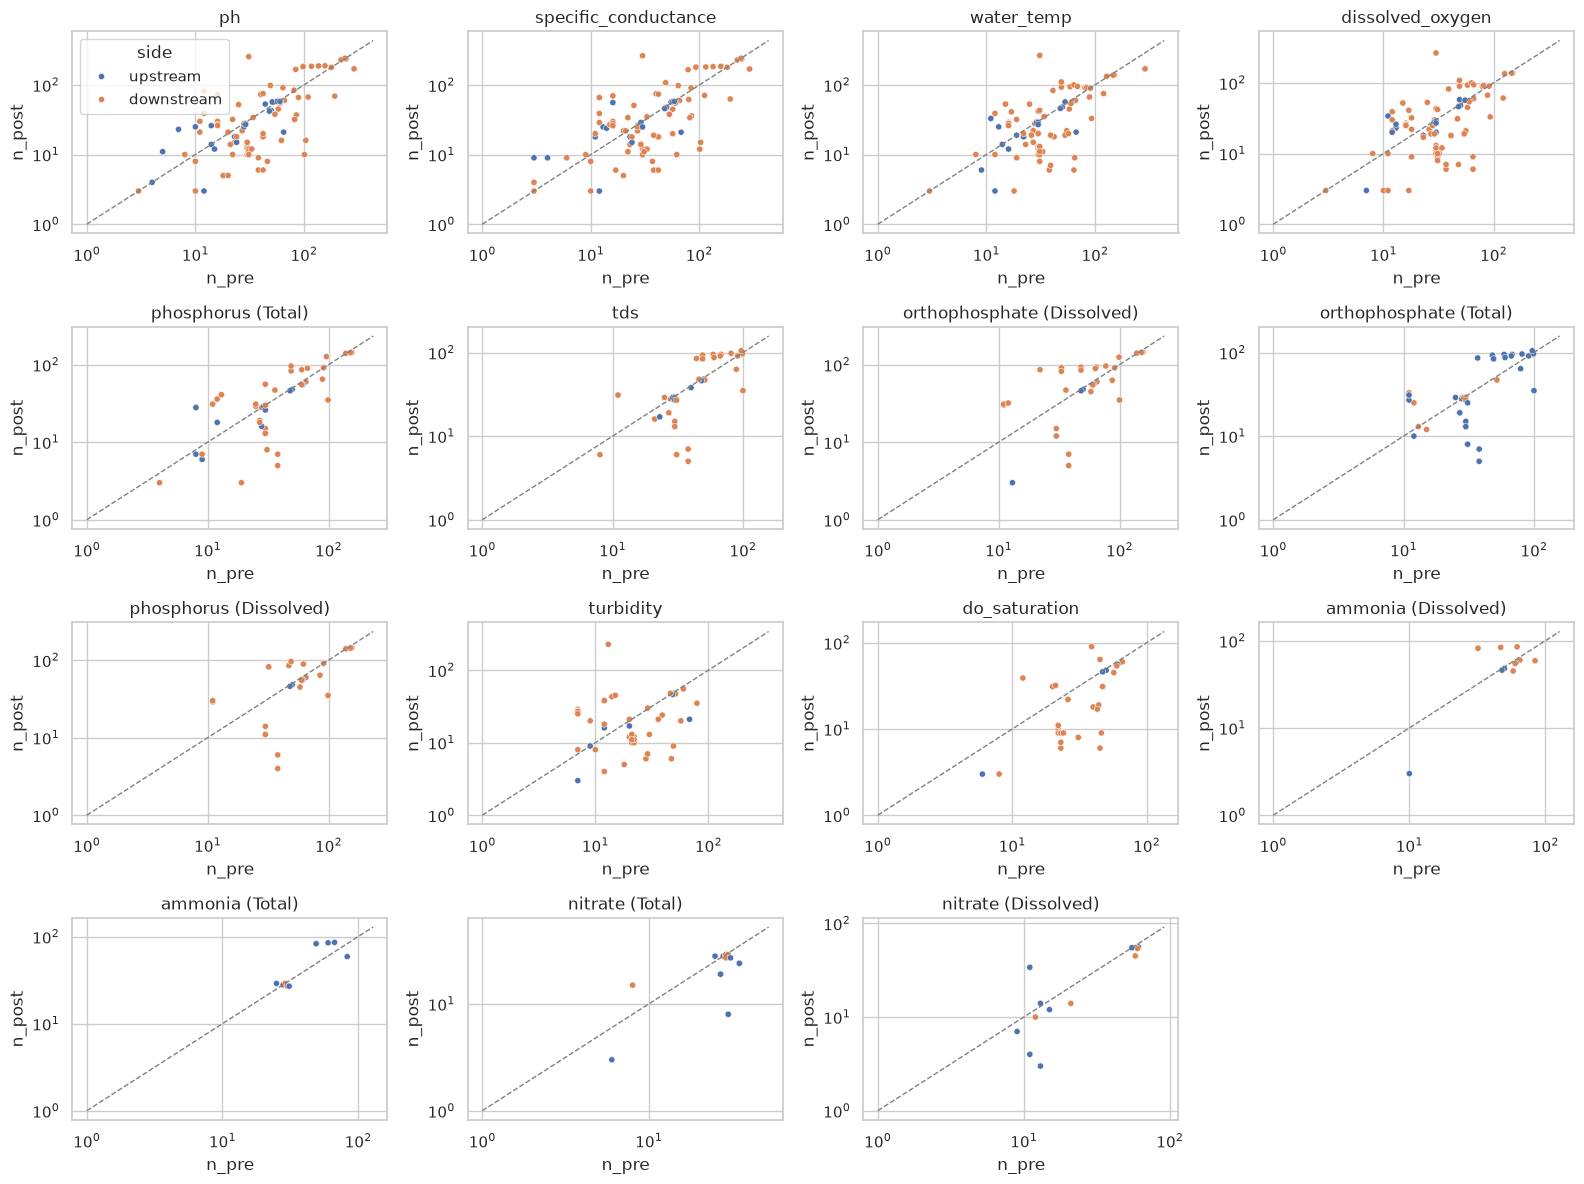

In [5]:
# Samples per pair, pre vs post (log scale). Points far from the diagonal are unbalanced pairs.
#  - Each point is one dam-station pair for that series: one station paired with one dam, measured for that  
#    parameter.                                                                                              
#  - x-axis (n_pre): how many samples that pair has in the 5 years before removal.                           
#  - y-axis (n_post): how many it has in the 5 years after.
#  - Gray dashed diagonal: equal before and after. Points above it have more samples after; points below have more before.

pairs = (df.groupby(["pair", "series", "side"])
           .agg(n_pre=("post", lambda p: (p == 0).sum()), n_post=("post", "sum"))
           .reset_index())
fig, axes = facet_axes(len(SERIES))
for ax, series in zip(axes, SERIES):
    rows = pairs[pairs["series"] == series]
    sns.scatterplot(data=rows, x="n_pre", y="n_post", hue="side", ax=ax, s=20, legend=ax is axes[0])
    lim = [1, max(rows[["n_pre", "n_post"]].max().max(), 10) * 1.5]
    ax.plot(lim, lim, color="gray", lw=1, ls="--")
    ax.set(xscale="log", yscale="log", title=series)
fig.tight_layout()

Text(0.5, 1.0, 'Rows by year from removal')

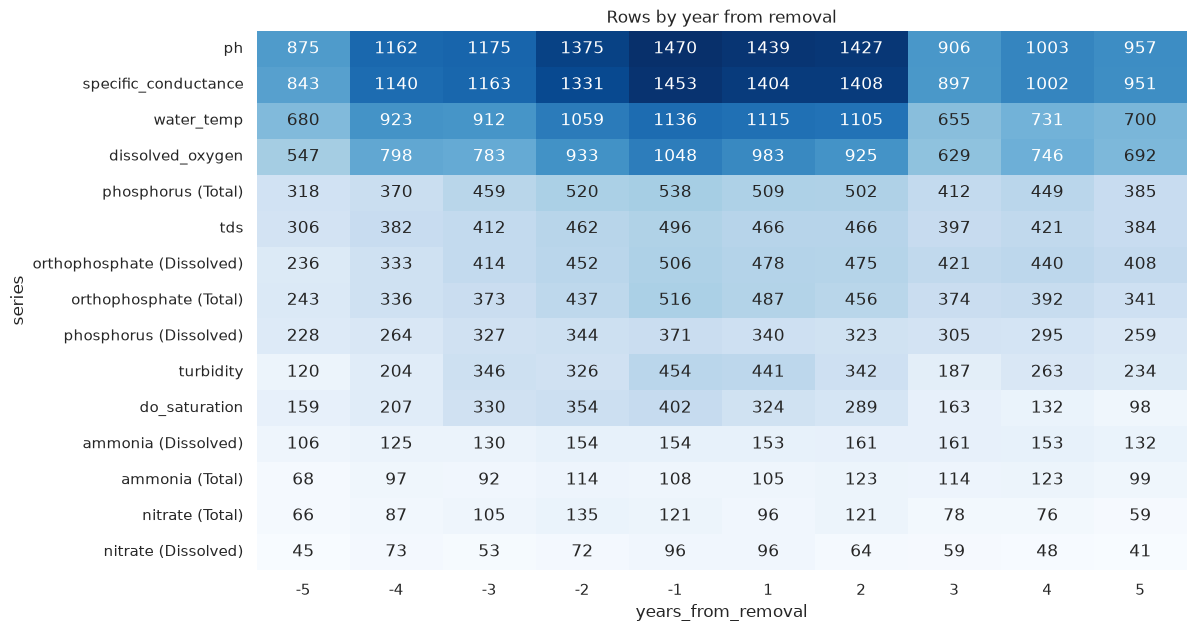

In [6]:
# Rows by year from removal (removal year 0 is excluded by design).
counts = df.pivot_table(index="series", columns="years_from_removal", values="y",
                        aggfunc="count", fill_value=0).loc[SERIES]
plt.figure(figsize=(12, 0.4 * len(SERIES) + 1))
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Rows by year from removal")

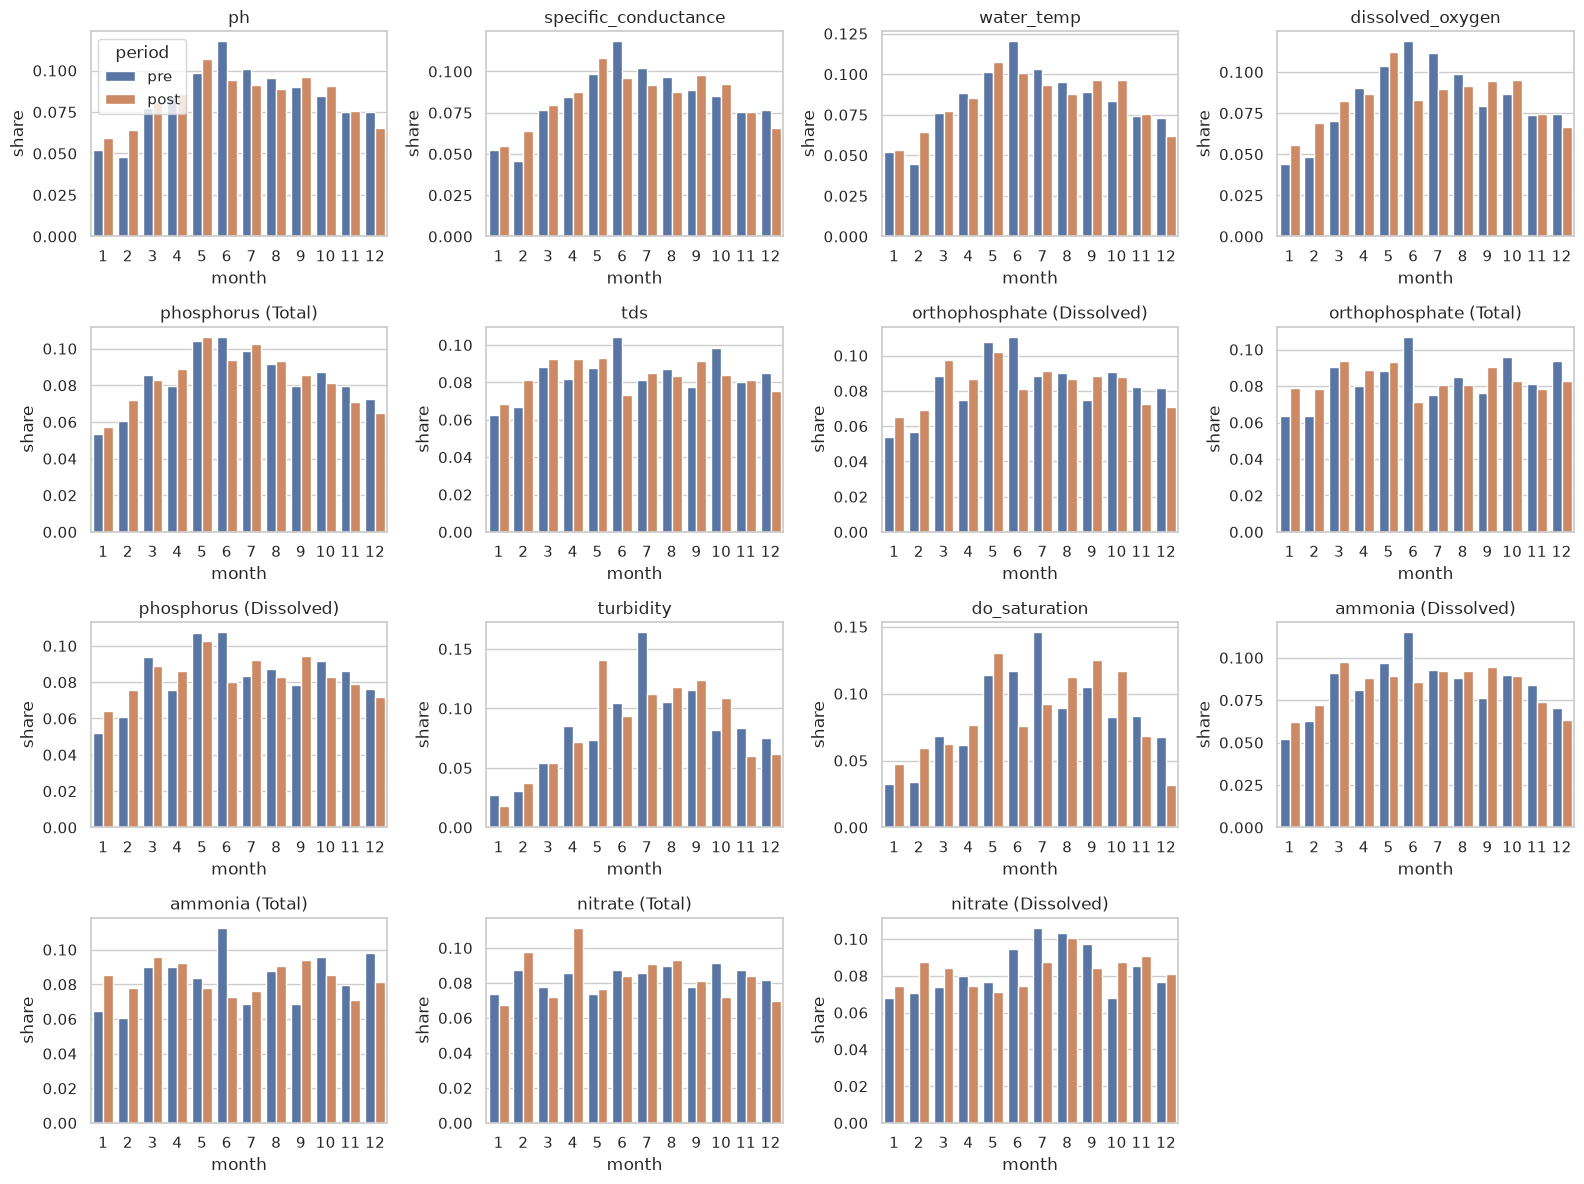

In [7]:
# Sampling months, pre vs post: if post samples are more summer-heavy than
# pre, seasonality alone shifts the raw comparison.
months = (df.groupby(["series", "period"])["month"].value_counts(normalize=True)
            .rename("share").reset_index())
fig, axes = facet_axes(len(SERIES))
for ax, series in zip(axes, SERIES):
    sns.barplot(data=months[months["series"] == series], x="month", y="share", hue="period",
                hue_order=["pre", "post"], ax=ax)
    ax.set_title(series)
    if ax is not axes[0]:
        ax.get_legend().remove()
fig.tight_layout()

In [8]:
# Provider mix pre vs post (NWIS = USGS, STORET = states and others): a change in sample provider
# can look like a change in water quality.
(df.groupby(["series", "period"])["provider"].value_counts(normalize=True)
   .mul(100).round(1).unstack(fill_value=0))

provider                            NWIS  STORET
series                     period               
ammonia (Dissolved)        post    100.0     0.0
                           pre     100.0     0.0
ammonia (Total)            post    100.0     0.0
                           pre     100.0     0.0
dissolved_oxygen           post     37.8    62.2
                           pre      30.0    70.0
do_saturation              post     61.2    38.8
                           pre      48.1    51.9
nitrate (Dissolved)        post     51.3    48.7
                           pre      56.6    43.4
nitrate (Total)            post     38.8    61.2
                           pre      33.1    66.9
orthophosphate (Dissolved) post     34.6    65.4
                           pre      35.0    65.0
orthophosphate (Total)     post     28.1    71.9
                           pre      24.9    75.1
ph                         post     31.1    68.9
                           pre      30.6    69.4
phosphorus (Dissolved)     post     50.5    49.5
                           pre      43.0    57.0
phosphorus (Total)         post     41.0    59.0
                           pre      37.7    62.3
specific_conductance       post     32.7    67.3
                           pre      32.1    67.9
tds                        post     38.7    61.3
                           pre      36.4    63.6
turbidity                  post     40.3    59.7
                           pre      32.3    67.7
water_temp                 post     42.9    57.1
                           pre      39.8    60.2

## 3. Value distributions

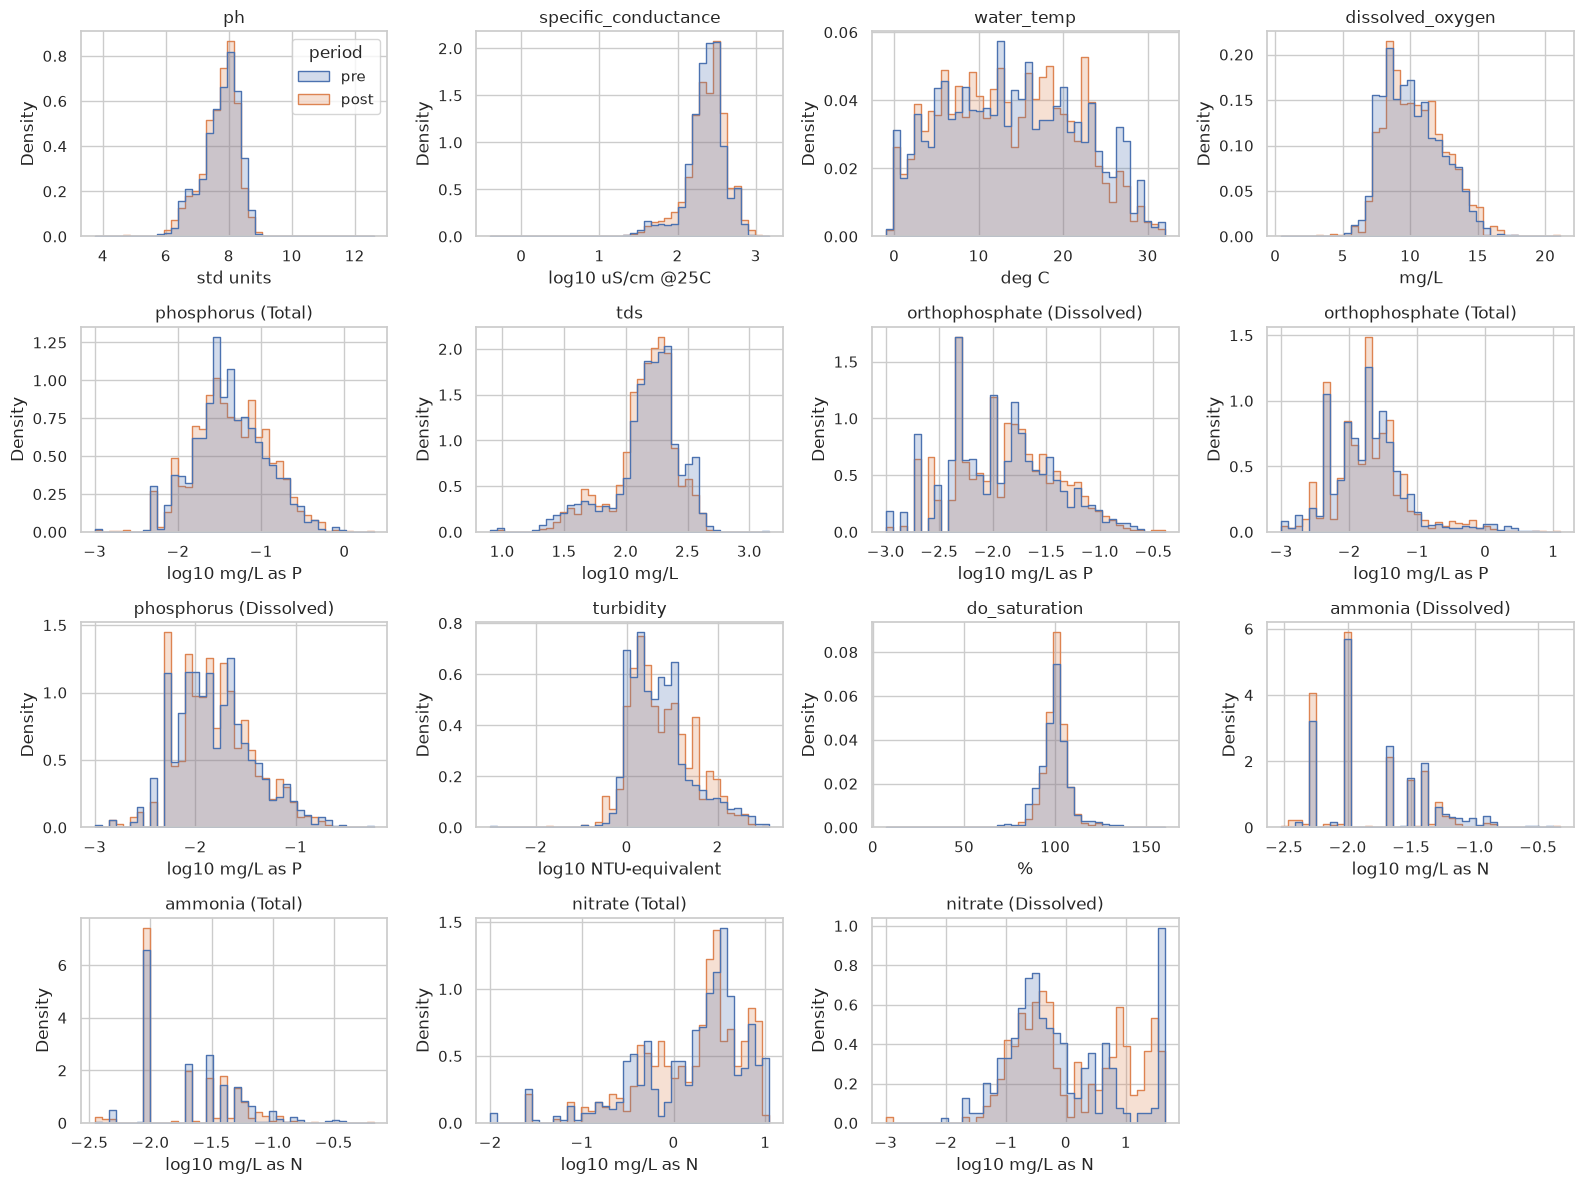

In [9]:
fig, axes = facet_axes(len(SERIES))
for ax, series in zip(axes, SERIES):
    rows = df[df["series"] == series]
    sns.histplot(data=rows, x="y", hue="period", hue_order=["pre", "post"], bins=40,
                 element="step", stat="density", common_norm=False, ax=ax, legend=ax is axes[0])
    ax.set(title=series, xlabel=y_label(series))
fig.tight_layout()

## 4. Seasonality

Why monthly climate matters: how much each parameter moves through the year, compared with any before/after shift.

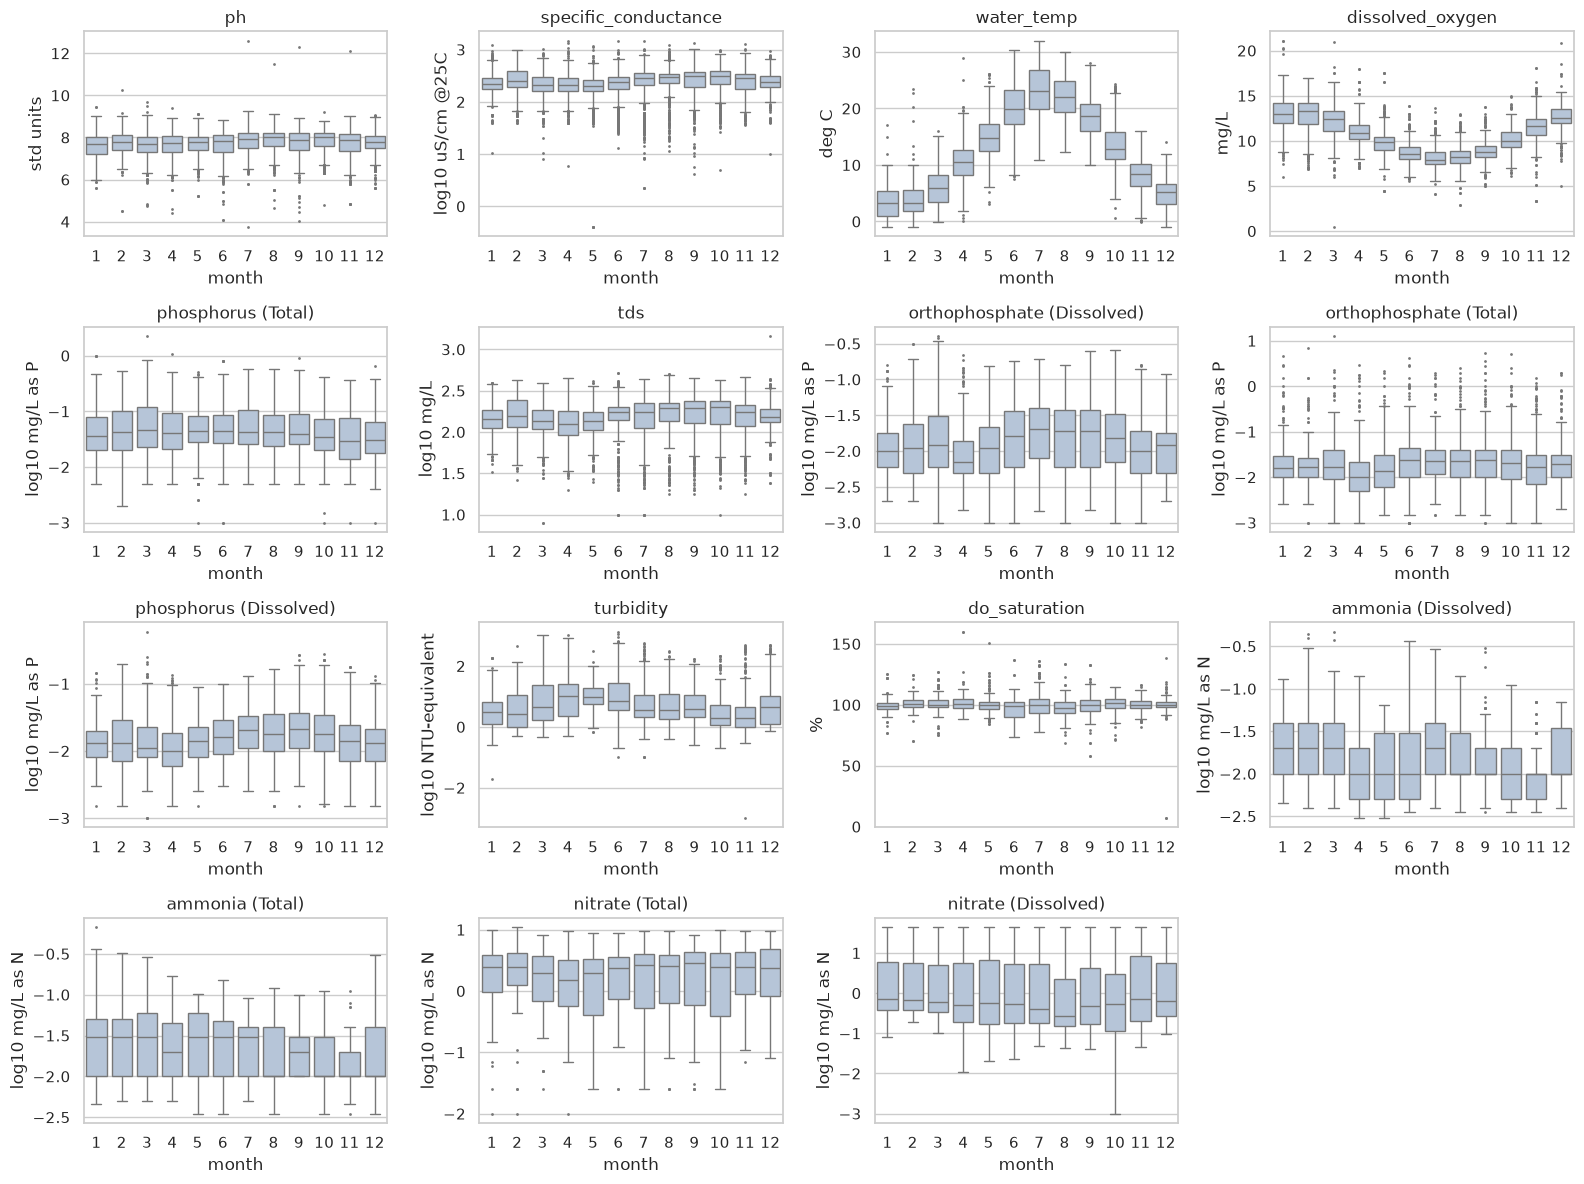

In [10]:
fig, axes = facet_axes(len(SERIES))
for ax, series in zip(axes, SERIES):
    sns.boxplot(data=df[df["series"] == series], x="month", y="y", ax=ax,
                color="lightsteelblue", fliersize=1)
    ax.set(title=series, ylabel=y_label(series))
fig.tight_layout()

Correlation: 0.89


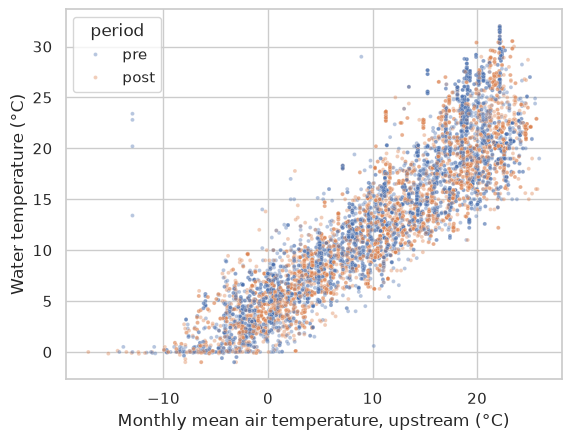

In [11]:
# Water temperature vs that month's upstream air temperature.
rows = df[df["parameter_std"] == "water_temp"].dropna(subset=["air_temp_mean_c"])
ax = sns.scatterplot(data=rows, x="air_temp_mean_c", y="y", hue="period", hue_order=["pre", "post"],
                     s=8, alpha=0.4)
ax.set(xlabel="Monthly mean air temperature, upstream (°C)", ylabel="Water temperature (°C)")
print(f"Correlation: {rows['air_temp_mean_c'].corr(rows['y']):.2f}")

## 5. Before vs after

**Anomaly** = value minus the station's average for that parameter and calendar month (over both periods). It removes each station's seasonal cycle and level, so a before/after shift stands out. It's a quick EDA device; the models in section 9 use month terms instead.

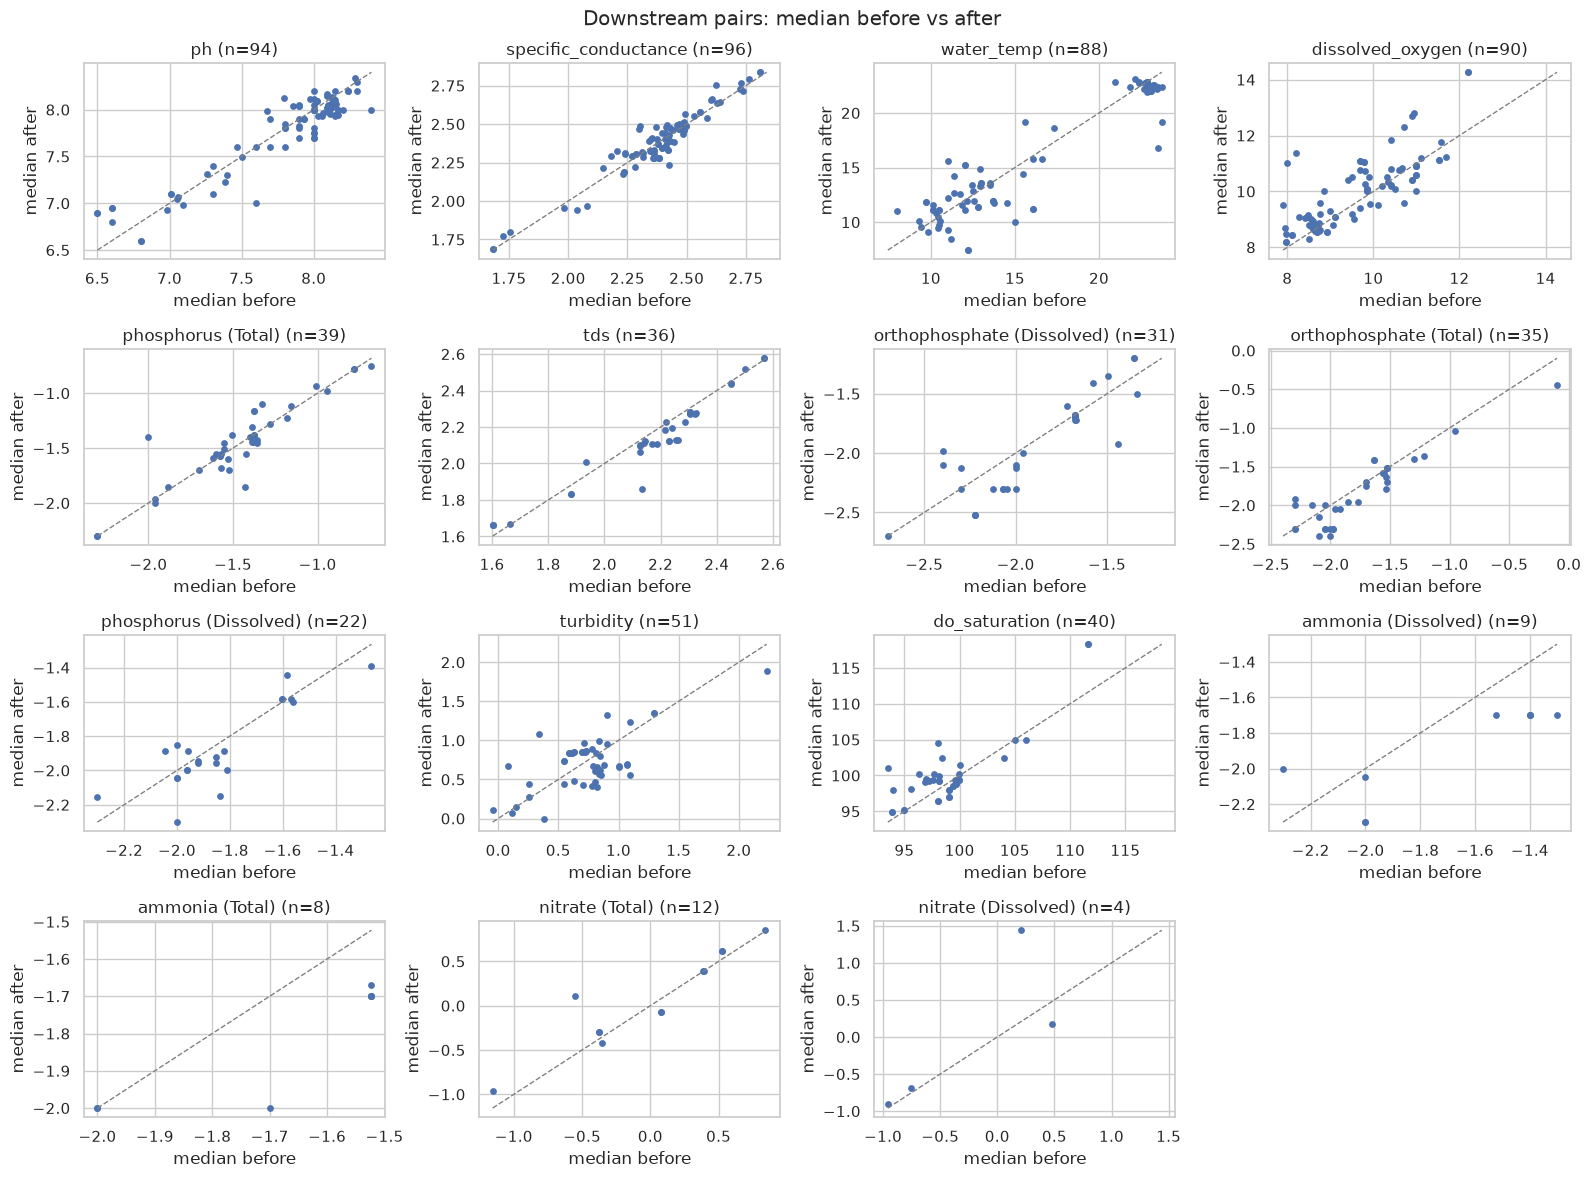

In [12]:
# Interpretation
# - Above the diagonal: Post-removal median increased.
# - Below the diagonal: Post-removal median decreased.
# - On the diagonal: No change in median.
# - n: Number of downstream pairs with measurements in both periods.
    
df["anomaly"] = df["y"] - df.groupby(["station_id", "series", "month"])["y"].transform("mean")

# One point per downstream pair: median before vs median after (raw values).
medians = (df[df["side"] == "downstream"]
           .groupby(["pair", "series", "period"])["y"].median().unstack().dropna())
fig, axes = facet_axes(len(SERIES))
for ax, series in zip(axes, SERIES):
    if series not in medians.index.get_level_values("series"):
        continue
    rows = medians.xs(series, level="series")
    ax.scatter(rows["pre"], rows["post"], s=15)
    lim = [rows.min().min(), rows.max().max()]
    ax.plot(lim, lim, color="gray", ls="--", lw=1)
    ax.set(title=f"{series} (n={len(rows)})", xlabel="median before", ylabel="median after")
fig.suptitle("Downstream pairs: median before vs after")
fig.tight_layout()

,pairs,median_change,pct_increased
series,,,
ammonia (Dissolved),9,-0.169018,11
ammonia (Total),8,-0.053895,12
dissolved_oxygen,90,-0.000037,48
do_saturation,40,0.332736,60
nitrate (Dissolved),4,0.103369,75
nitrate (Total),12,0.008508,67
orthophosphate (Dissolved),31,-0.006079,48
orthophosphate (Total),35,-0.049302,29
ph,94,-0.036987,41


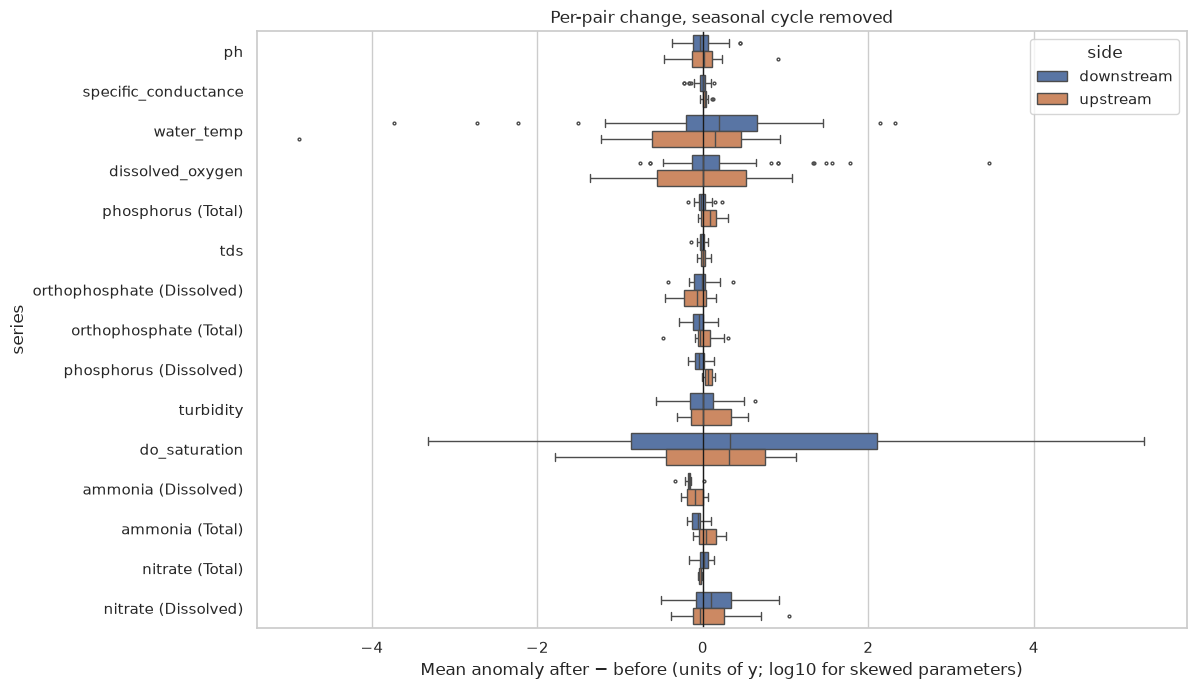

In [13]:
# Change per pair after removing the seasonal cycle: mean anomaly after - before.
change = (df.groupby(["pair", "AR_ID", "series", "side", "period"])["anomaly"].mean()
            .unstack().dropna())
change["change"] = change["post"] - change["pre"]
change = change.reset_index()

plt.figure(figsize=(12, 0.45 * len(SERIES) + 1))
sns.boxplot(data=change, y="series", x="change", hue="side", order=SERIES,
            hue_order=["downstream", "upstream"], fliersize=2)
plt.axvline(0, color="k", lw=1)
plt.xlabel("Mean anomaly after − before (units of y; log10 for skewed parameters)")
plt.title("Per-pair change, seasonal cycle removed")

# Share of downstream pairs that went up, per parameter.
(change[change["side"] == "downstream"].groupby("series")["change"]
   .agg(pairs="size", median_change="median", pct_increased=lambda c: round(100 * (c > 0).mean())))

## 6. Event study

Mean anomaly by year from removal. A removal effect would primarily show as a step (or trend) after year 0 at downstream stations but not upstream ones.

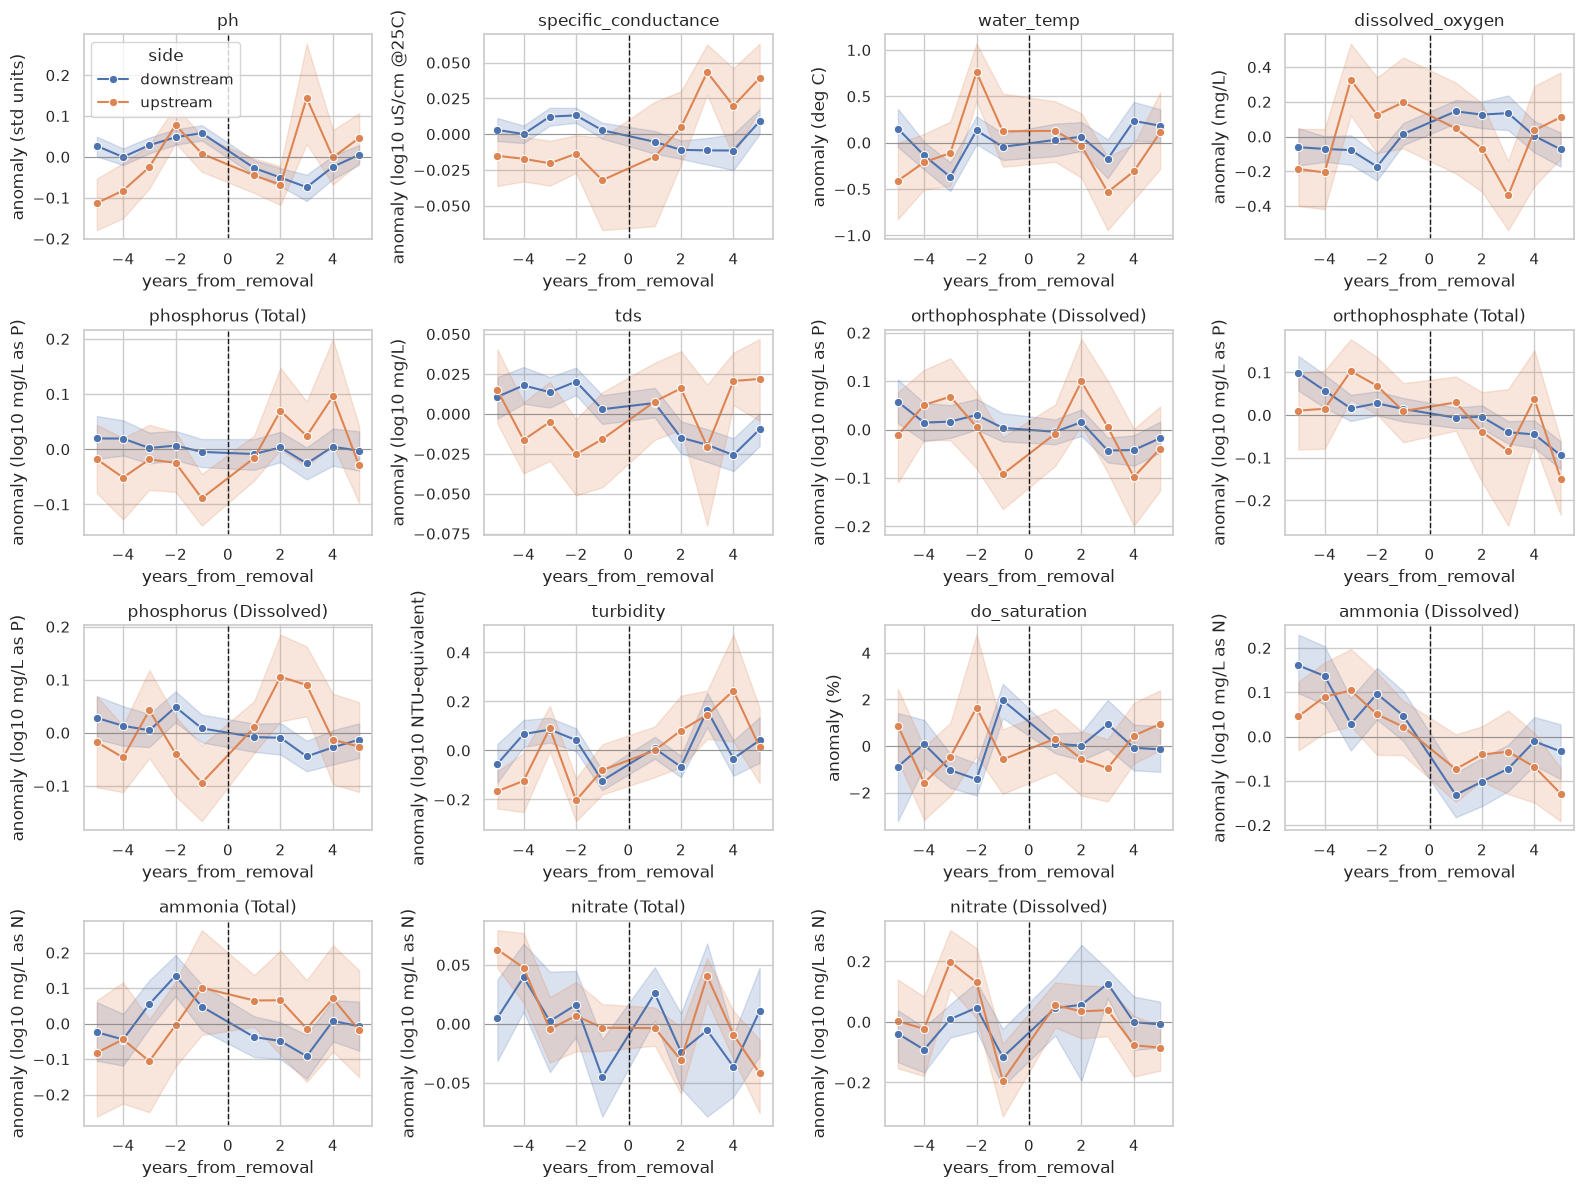

In [14]:
fig, axes = facet_axes(len(SERIES))
for ax, series in zip(axes, SERIES):
    rows = df[df["series"] == series]
    sns.lineplot(data=rows, x="years_from_removal", y="anomaly", hue="side",
                 hue_order=["downstream", "upstream"], errorbar=("ci", 95), marker="o",
                 ax=ax, legend=ax is axes[0])
    ax.axvline(0, color="k", ls="--", lw=1)
    ax.axhline(0, color="gray", lw=0.5)
    ax.set(title=series, ylabel=f"anomaly ({y_label(series)})")
fig.tight_layout()

## 7. Dam and watershed covariates

One row per dam-station pair (these columns don't vary within a pair).

In [15]:
COVARIATES = ["dam_height_ft", "dam_age_at_removal", "upstream_area_km2", "network_distance_km",
              "pct_forest", "pct_developed", "pct_agriculture", "pct_wetlands", "pct_water"]
pair_table = df.drop_duplicates("pair")[["pair", "AR_ID", "side", "removal_year",
                                         "land_cover_year", "watershed_truncated"] + COVARIATES]
print(f"Pairs: {len(pair_table)}; land cover from after removal: "
      f"{int((pair_table['land_cover_year'] >= pair_table['removal_year']).sum())}; "
      f"truncated watersheds: {int(pair_table['watershed_truncated'].sum())}")
pair_table[COVARIATES].describe().round(1)

Pairs: 133; land cover from after removal: 3; truncated watersheds: 0


,dam_height_ft,dam_age_at_removal,upstream_area_km2,network_distance_km,pct_forest,pct_developed,pct_agriculture,pct_wetlands,pct_water
count,105.0,23.0,133.0,133.0,133.0,133.0,133.0,133.0,133.0
mean,12.5,103.2,22298.3,5.7,56.0,13.1,22.0,2.6,0.7
std,11.1,68.1,31113.6,3.0,20.4,11.1,16.4,5.5,1.3
min,2.0,39.0,0.0,0.1,0.8,0.0,0.0,0.0,0.0
25%,5.0,56.5,219.0,3.3,48.8,7.5,9.8,0.7,0.1
50%,9.0,91.0,938.1,5.7,62.4,10.3,23.3,1.8,0.4
75%,15.0,109.0,67242.2,8.7,65.0,16.0,26.6,1.9,0.9
max,60.0,290.0,67246.2,10.0,90.4,77.7,65.0,42.8,7.6


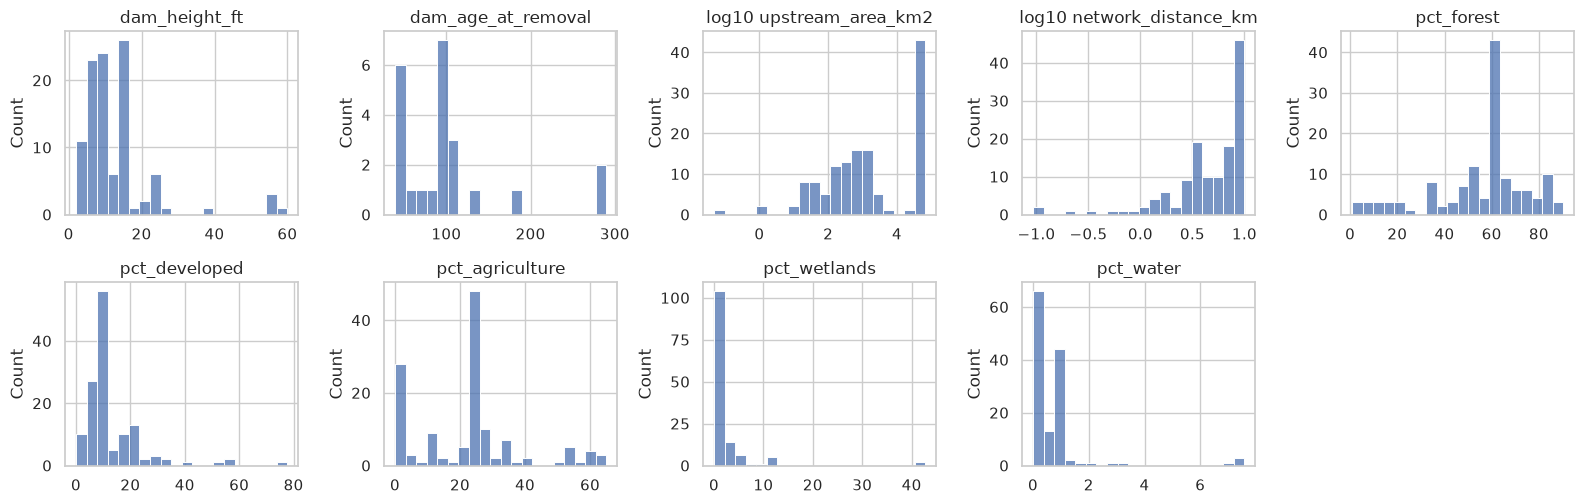

In [16]:
# Show covariate distributions
fig, axes = facet_axes(len(COVARIATES), ncols=5, width=3.2, height=2.6)
for ax, column in zip(axes, COVARIATES):
    values = pair_table[column].dropna()
    if column in ("upstream_area_km2", "network_distance_km"):
        values = np.log10(values.clip(lower=0.01))
        column = f"log10 {column}"
    sns.histplot(values, bins=20, ax=ax)
    ax.set(title=column, xlabel="")
fig.tight_layout()

Text(0.5, 1.0, 'Covariate correlations (Spearman), one row per pair')

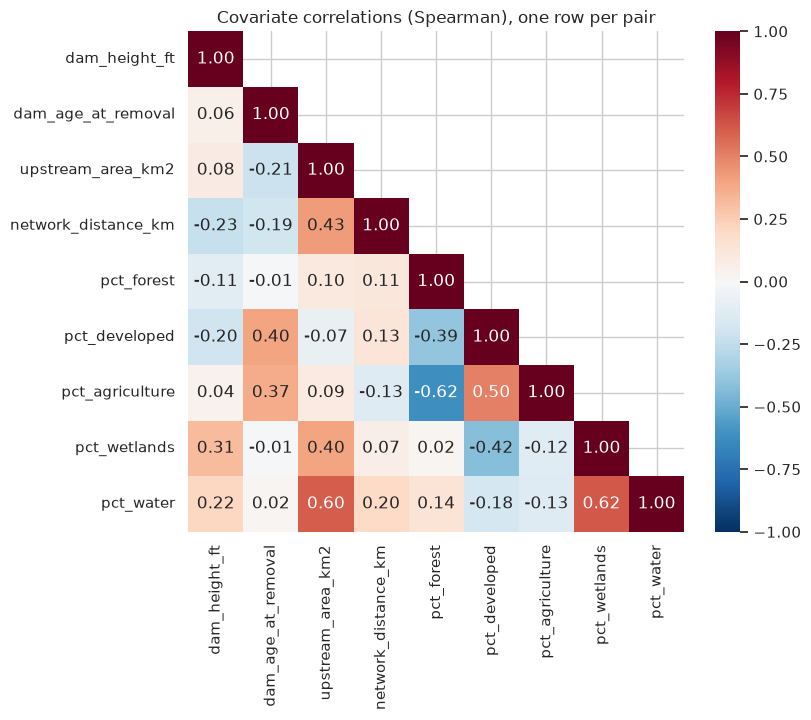

In [17]:
# Correlations between covariates (Spearman): strongly correlated pairs
# shouldn't both go into a small model.
corr = pair_table[COVARIATES].corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, mask=np.triu(np.ones_like(corr, bool), 1))
plt.title("Covariate correlations (Spearman), one row per pair")

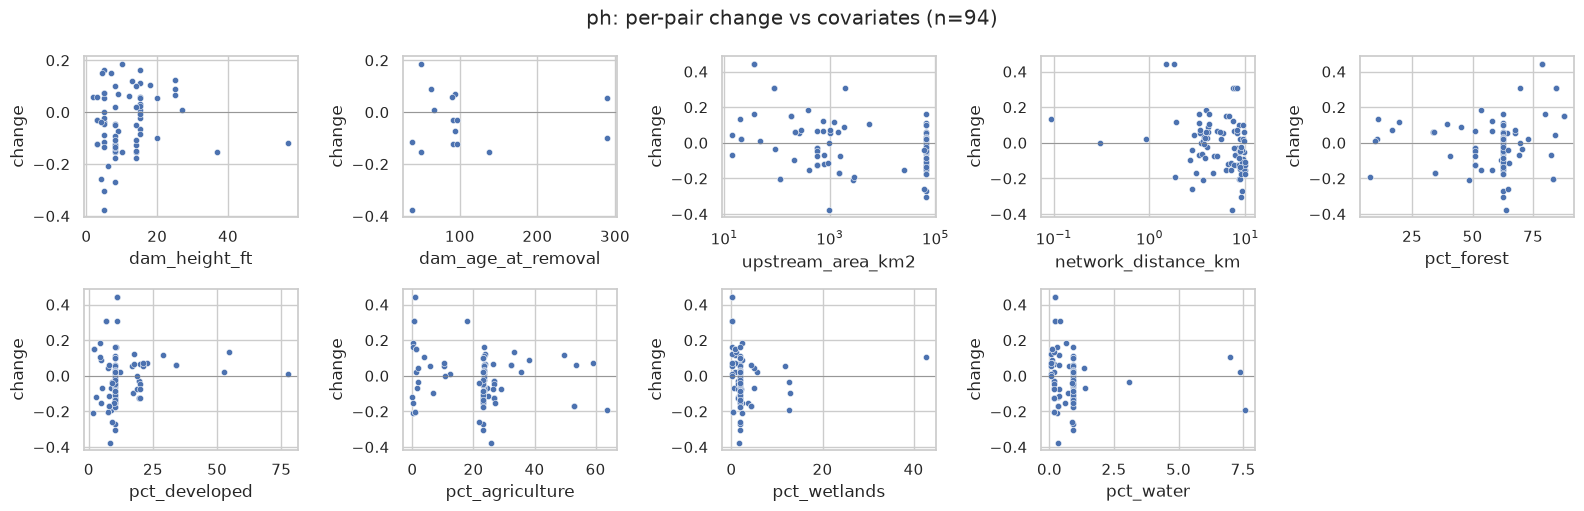

In [18]:
# Does the per-pair change (section 5) relate to the covariates? Downstream pairs only.
# FOCUS: one series at a time; change it to look at others.
FOCUS = SERIES[0]
rows = change[(change["series"] == FOCUS) & (change["side"] == "downstream")].merge(
    pair_table[["pair"] + COVARIATES], on="pair")
fig, axes = facet_axes(len(COVARIATES), ncols=5, width=3.2, height=2.6)
for ax, column in zip(axes, COVARIATES):
    sns.scatterplot(data=rows, x=column, y="change", ax=ax, s=20)
    ax.axhline(0, color="gray", lw=0.5)
    if column in ("upstream_area_km2", "network_distance_km"):
        ax.set_xscale("log")
fig.suptitle(f"{FOCUS}: per-pair change vs covariates (n={len(rows)})")
fig.tight_layout()

## 8. Climate vs water quality

Text(0.5, 1.0, 'Correlation with upstream climate (Spearman)')

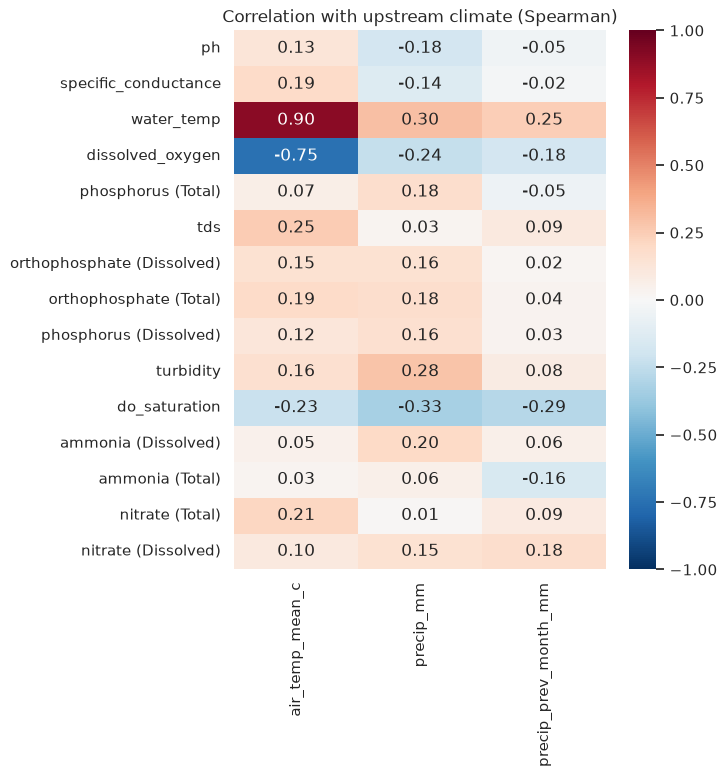

In [19]:
# Spearman correlation of each parameter with the climate columns.
CLIMATE = ["air_temp_mean_c", "precip_mm", "precip_prev_month_mm"]
climate_corr = pd.DataFrame({
    series: df.loc[df["series"] == series, ["y"] + CLIMATE].corr(method="spearman")["y"][CLIMATE]
    for series in SERIES
}).T
plt.figure(figsize=(6, 0.4 * len(SERIES) + 1))
sns.heatmap(climate_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation with upstream climate (Spearman)")

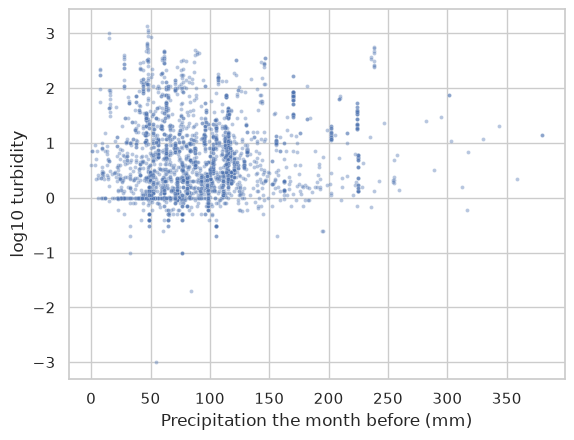

In [20]:
# Turbidity vs rain the month before (where turbidity is present).
rows = df[df["parameter_std"] == "turbidity"].dropna(subset=["precip_prev_month_mm"])
if len(rows):
    ax = sns.scatterplot(data=rows, x="precip_prev_month_mm", y="y", s=8, alpha=0.4)
    ax.set(xlabel="Precipitation the month before (mm)", ylabel="log10 turbidity")

## 9. A first simple model per parameter (preview)

Two linear mixed models per parameter, with a random intercept per dam-station pair (repeated samples at one station aren't independent). `y` is log10 for skewed parameters, so `10 ** effect − 1` is the proportional change.

- **Before/after (downstream only):** `y ~ post + C(month) + air_temp_mean_c + precip_prev_month_mm`. `post` is the average change after removal, given season and weather.
- **BACI (dams with upstream controls):** adds `downstream` and `post:downstream`. The interaction is the change downstream beyond any change upstream (e.g. a regional trend).

Exploratory only: no censoring model, no distance or dam covariates, and small samples. Rows with missing climate are dropped.

In [21]:
# Interpretation:
#    - effect: the estimated change after removal.                                                             
#    - Before/after rows: the change at downstream stations, after accounting for month, air temperature and 
#      the previous month's rain.                                                                            
#    - BACI rows: the downstream change minus the upstream change at the same dams.                          
#    - Units: the parameter's own units for pH, temperature, DO and DO saturation. For log-scale parameters, 
#      read pct_change instead.                                                                              
#    - ci_low / ci_high: the 95% interval. If it includes 0, the data are consistent with no change.           
#    - p: below 0.05 is the usual "significant" cutoff.                                                        
#    - rows / pairs: the data behind each fit.                                                                 
                                                                     

def fit(formula, rows, term):
    """Coefficient, 95% CI and p-value of one term, or None if the fit fails."""
    try:
        result = smf.mixedlm(formula, rows, groups=rows["pair"]).fit(reml=True, method="lbfgs")
    except Exception as exc:  # singular fits etc. with very little data
        return {"error": str(exc)[:60]}
    low, high = result.conf_int().loc[term]
    return {"effect": result.params[term], "ci_low": low, "ci_high": high,
            "p": result.pvalues[term], "rows": int(result.nobs), "pairs": rows["pair"].nunique()}


COVARIATE_TERMS = "C(month) + air_temp_mean_c + precip_prev_month_mm"
results = []
for series in SERIES:
    rows = df[df["series"] == series].dropna(subset=["air_temp_mean_c", "precip_prev_month_mm", "side"])
    downstream = rows[rows["side"] == "downstream"]
    if downstream["pair"].nunique() >= 3:
        results.append({"series": series, "model": "before/after (downstream)",
                        **fit(f"y ~ post + {COVARIATE_TERMS}", downstream, "post")})

    # BACI: dams that have both a downstream and an upstream pair.
    sides = rows.groupby("AR_ID")["side"].nunique()
    baci = rows[rows["AR_ID"].isin(sides[sides == 2].index)].assign(
        downstream=lambda r: (r["side"] == "downstream").astype(int))
    if baci["AR_ID"].nunique() >= 2:
        results.append({"series": series, "model": "BACI (post x downstream)",
                        **fit(f"y ~ post * downstream + {COVARIATE_TERMS}", baci, "post:downstream")})

results = pd.DataFrame(results)
results["log_scale"] = results["series"].str.split(" (", regex=False).str[0].isin(LOG_PARAMETERS)
# For log10 parameters: the effect as a % change.
results["pct_change"] = np.where(results["log_scale"], (10 ** results["effect"] - 1) * 100, np.nan)
results.round(4)

/home/creighton.jo/.conda/envs/dam-removal/lib/python3.11/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/home/creighton.jo/.conda/envs/dam-removal/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2429: SingularMatrixWarning: The random effects covariance matrix is singular.
  scale = self.get_scale(fe_params, cov_re_unscaled, vcomp_unscaled)
/tmp/ipykernel_2266043/1857899142.py:16: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  result = smf.mixedlm(formula, rows, groups=rows["pair"]).fit(reml=True, method="lbfgs")
/tmp/ipykernel_2266043/1857899142.py:16: SingularMatrixWarning: The random effects covariance matrix is singular.
  result = smf.mixedlm(formula, rows, groups=rows["pair"]).fit(reml=True, method="lbfgs")
/tmp/ipykernel_2266043/1857899142.py:16: ConvergenceWarning: The Hessian matrix at the estimated parameter values is n

,series,model,effect,ci_low,ci_high,p,rows,pairs,log_scale,pct_change
0,ph,before/after (downstream),-0.0823,-0.0979,-0.0666,0.0000,10325,94,False,NaN
1,ph,BACI (post x downstream),0.0923,0.0383,0.1464,0.0008,3056,37,False,NaN
2,specific_conductance,before/after (downstream),-0.0120,-0.0176,-0.0063,0.0000,10312,96,True,-2.7166
3,specific_conductance,BACI (post x downstream),-0.0126,-0.0339,0.0088,0.2488,2873,35,True,-2.8504
4,water_temp,before/after (downstream),-0.0526,-0.1845,0.0793,0.4345,7795,88,False,NaN
5,water_temp,BACI (post x downstream),0.4171,-0.0877,0.9218,0.1053,2184,34,False,NaN
6,dissolved_oxygen,before/after (downstream),0.2102,0.1490,0.2714,0.0000,6905,90,False,NaN
7,dissolved_oxygen,BACI (post x downstream),0.4943,0.2595,0.7292,0.0000,2294,38,False,NaN
8,phosphorus (Total),before/after (downstream),-0.0172,-0.0386,0.0041,0.1140,3737,39,True,-3.8867
9,phosphorus (Total),BACI (post x downstream),-0.0791,-0.1499,-0.0083,0.0286,1193,14,True,-16.6454


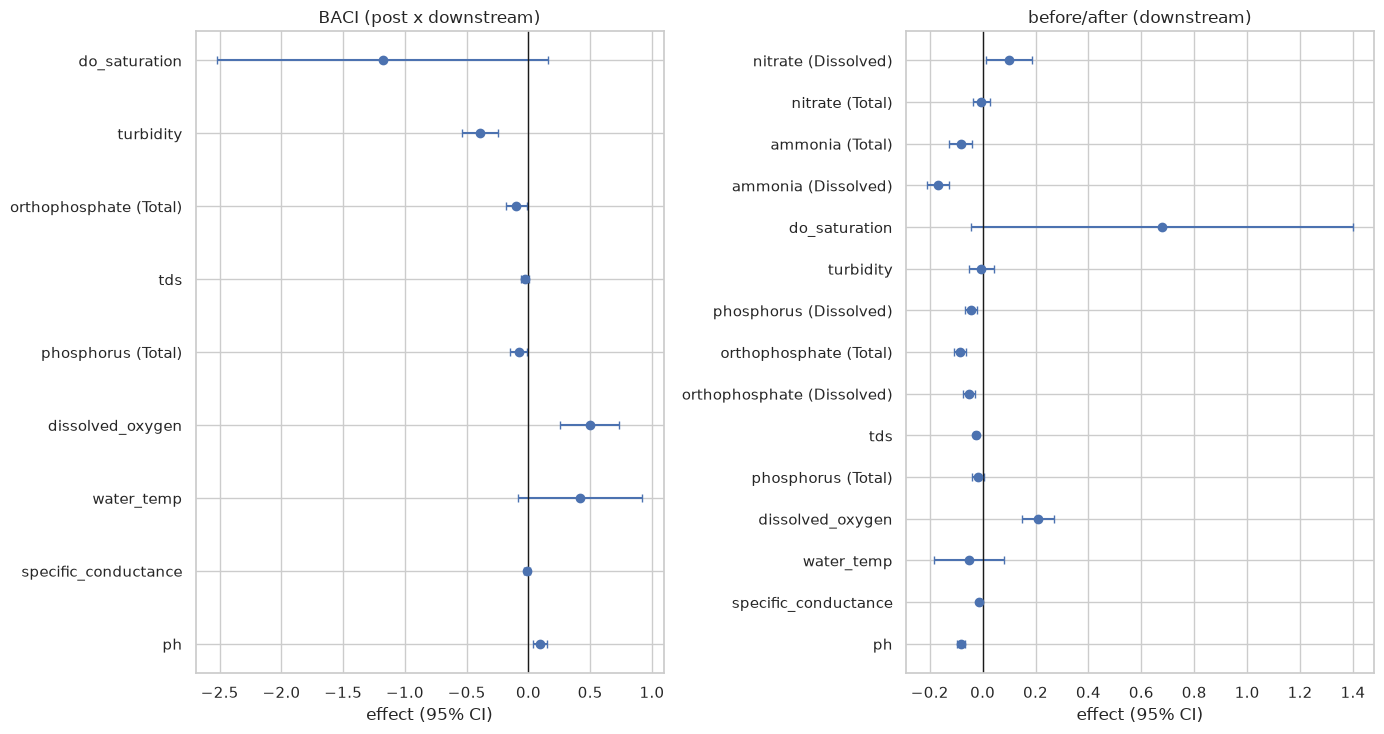

In [22]:
# Effects with 95% CIs (units of y; log10 for skewed parameters). Intervals
# that cross 0 are consistent with no change.
ok = results.dropna(subset=["effect"])
fig, axes = plt.subplots(1, 2, figsize=(14, 0.4 * len(SERIES) + 1.5), sharey=False)
for ax, (model, rows) in zip(axes, ok.groupby("model")):
    ax.errorbar(rows["effect"], rows["series"],
                xerr=[rows["effect"] - rows["ci_low"], rows["ci_high"] - rows["effect"]],
                fmt="o", capsize=3)
    ax.axvline(0, color="k", lw=1)
    ax.set(title=model, xlabel="effect (95% CI)")
fig.tight_layout()

The results above do not consider distance from dam removal. Below, we will explore if filtering stations by distance to dam removal sites reveals water quality trends.

## 10. Change vs distance from the dam

Do stations closer to the dam change more? Uses the per-pair change from section 5 (mean seasonal anomaly after − before) and
`network_distance_km`.

Caveats: pairs with few samples show bigger changes by chance, and distance goes with river size (bigger rivers are steadier), so
upstream pairs at similar distances are shown as a reference.

In [23]:
# One row per pair with its distance
from scipy import stats

dist = change.merge(pair_table[["pair", "network_distance_km", "upstream_area_km2"]], on="pair")
dist["abs_change"] = dist["change"].abs()

# Series with enough pairs to say anything about distance.
MAIN = [s for s in SERIES if dist.loc[dist["series"] == s, "pair"].nunique() >= 15]
NEAR_KM = 15  # "near" cutoff used below; try 5, 10, 25
print(f"Series with >= 15 pairs: {MAIN}")
print(dist.groupby("side")["network_distance_km"].describe().round(1))

Series with >= 15 pairs: ['ph', 'specific_conductance', 'water_temp', 'dissolved_oxygen', 'phosphorus (Total)', 'tds', 'orthophosphate (Dissolved)', 'orthophosphate (Total)', 'phosphorus (Dissolved)', 'turbidity', 'do_saturation', 'nitrate (Total)']
            count  mean  std  min  25%  50%  75%   max
side                                                  
downstream  655.0   6.5  2.7  0.1  3.9  7.3  8.9  10.0
upstream    158.0   3.7  2.5  0.2  1.8  2.7  5.5   9.0


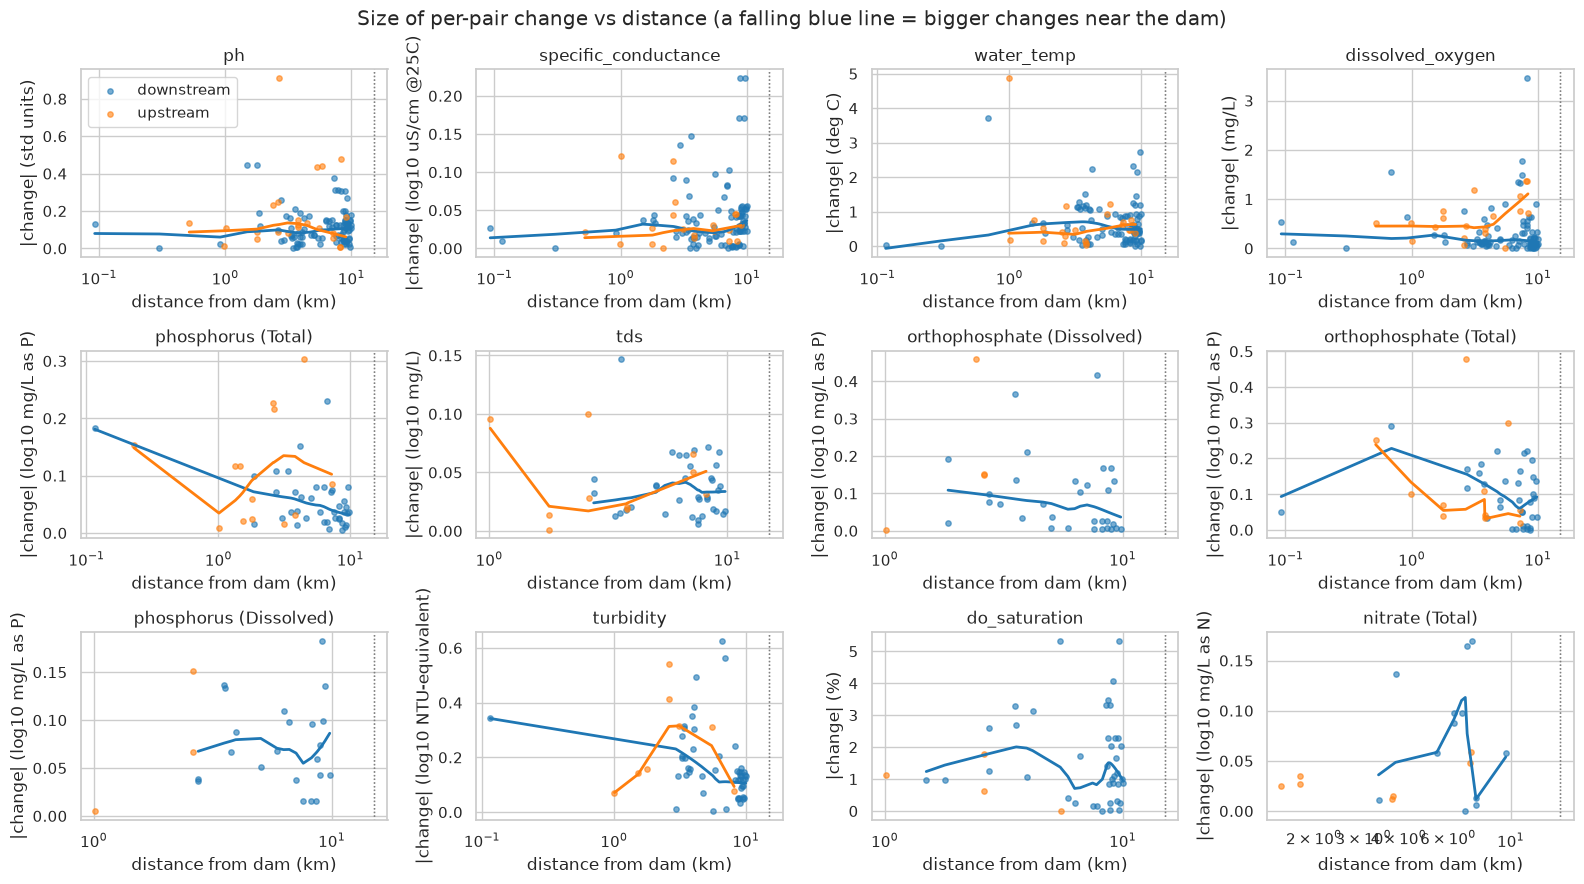

In [24]:
from statsmodels.nonparametric.smoothers_lowess import lowess as sm_lowess 

# Size of change vs distance, with a smoothed trend per side
fig, axes = facet_axes(len(MAIN))
for ax, series in zip(axes, MAIN):
  rows = dist[(dist["series"] == series) & (dist["network_distance_km"] > 0)]
  for side, color in [("downstream", "tab:blue"), ("upstream", "tab:orange")]:
      part = rows[rows["side"] == side]
      ax.scatter(part["network_distance_km"], part["abs_change"], s=15, color=color, alpha=0.6, label=side)
      if len(part) >= 8:
          smooth = sm_lowess(part["abs_change"], np.log10(part["network_distance_km"]), frac=0.7)
          ax.plot(10 ** smooth[:, 0], smooth[:, 1], color=color, lw=2)                                                          
      ax.axvline(NEAR_KM, color="gray", ls=":", lw=1)                                                                               
      ax.set(xscale="log", title=series, xlabel="distance from dam (km)", ylabel=f"|change| ({y_label(series)})")                                                                                
  axes[0].legend()                                                                                                                  
  fig.suptitle("Size of per-pair change vs distance (a falling blue line = bigger changes near the dam)")                           
  fig.tight_layout()                                                                   

In [25]:
# Rank correlation of change with distance                                                                                  
# Negative rho for |change| = closer stations change more.                                                                        
rows = []                                                                                                                         
for series in MAIN:                                                                                                               
  for side in ["downstream", "upstream"]:                                                                                       
      part = dist[(dist["series"] == series) & (dist["side"] == side)]                                                          
      if len(part) < 8:                                                                                                         
          continue                                                                                                              
      rho_abs, p_abs = stats.spearmanr(part["network_distance_km"], part["abs_change"])                                         
      rho, p = stats.spearmanr(part["network_distance_km"], part["change"])                                                     
      rows.append({"series": series, "side": side, "pairs": len(part),                                                          
                   "rho_abs_change": rho_abs, "p_abs": p_abs,                                                                   
                   "rho_signed_change": rho, "p_signed": p})                                                                    
pd.DataFrame(rows).round(3)          

,series,side,pairs,rho_abs_change,p_abs,rho_signed_change,p_signed
0,ph,downstream,94,0.065,0.533,-0.354,0.000
1,ph,upstream,23,0.054,0.807,-0.339,0.114
2,specific_conductance,downstream,96,0.224,0.028,-0.419,0.000
3,specific_conductance,upstream,20,0.109,0.647,-0.022,0.927
4,water_temp,downstream,88,-0.050,0.644,-0.170,0.114
5,water_temp,upstream,21,0.071,0.760,0.327,0.148
6,dissolved_oxygen,downstream,90,-0.146,0.169,0.124,0.243
7,dissolved_oxygen,upstream,19,0.464,0.045,-0.482,0.037
8,phosphorus (Total),downstream,39,-0.361,0.024,0.110,0.503
9,phosphorus (Total),upstream,13,0.179,0.559,0.063,0.837


median                         count  \
distance_band                          <5 km 5-15 km 15-40 km >40 km <5 km   
series                     side                                              
dissolved_oxygen           downstream  0.133   0.178      NaN    NaN    34   
                           upstream    0.451   0.916      NaN    NaN    13   
do_saturation              downstream  1.931   1.053      NaN    NaN     8   
                           upstream    1.125   0.000      NaN    NaN     3   
nitrate (Total)            downstream  0.074   0.073      NaN    NaN     2   
                           upstream    0.025   0.053      NaN    NaN     5   
orthophosphate (Dissolved) downstream  0.088   0.027      NaN    NaN    10   
                           upstream    0.151     NaN      NaN    NaN     4   
orthophosphate (Total)     downstream  0.159   0.072      NaN    NaN     9   
                           upstream    0.086   0.056      NaN    NaN     8   
ph                         downstream  0.073   0.113      NaN    NaN    35   
                           upstream    0.121   0.110      NaN    NaN    14   
phosphorus (Dissolved)     downstream  0.078   0.064      NaN    NaN     6   
                           upstream    0.067     NaN      NaN    NaN     3   
phosphorus (Total)         downstream  0.067   0.037      NaN    NaN    14   
                           upstream    0.089   0.085      NaN    NaN    12   
specific_conductance       downstream  0.023   0.030      NaN    NaN    33   
                           upstream    0.024   0.027      NaN    NaN    12   
tds                        downstream  0.020   0.035      NaN    NaN     7   
                           upstream    0.020   0.050      NaN    NaN     7   
turbidity                  downstream  0.202   0.121      NaN    NaN    20   
                           upstream    0.236   0.194      NaN    NaN     6   
water_temp                 downstream  0.668   0.453      NaN    NaN    30   
                           upstream    0.297   0.660      NaN    NaN    13   

                                                               
distance_band                         5-15 km 15-40 km >40 km  
series                     side                                
dissolved_oxygen           downstream      56        0      0  
                           upstream         6        0      0  
do_saturation              downstream      32        0      0  
                           upstream         1        0      0  
nitrate (Total)            downstream      10        0      0  
                           upstream         2        0      0  
orthophosphate (Dissolved) downstream      21        0      0  
                           upstream         0        0      0  
orthophosphate (Total)     downstream      26        0      0  
                           upstream         3        0      0  
ph                         downstream      59        0      0  
                           upstream         9        0      0  
phosphorus (Dissolved)     downstream      16        0      0  
                           upstream         0        0      0  
phosphorus (Total)         downstream      25        0      0  
                           upstream         1        0      0  
specific_conductance       downstream      63        0      0  
                           upstream         8        0      0  
tds                        downstream      29        0      0  
                           upstream         3        0      0  
turbidity                  downstream      31        0      0  
                           upstream         2        0      0  
water_temp                 downstream      58        0      0  
                           upstream         8        0      0

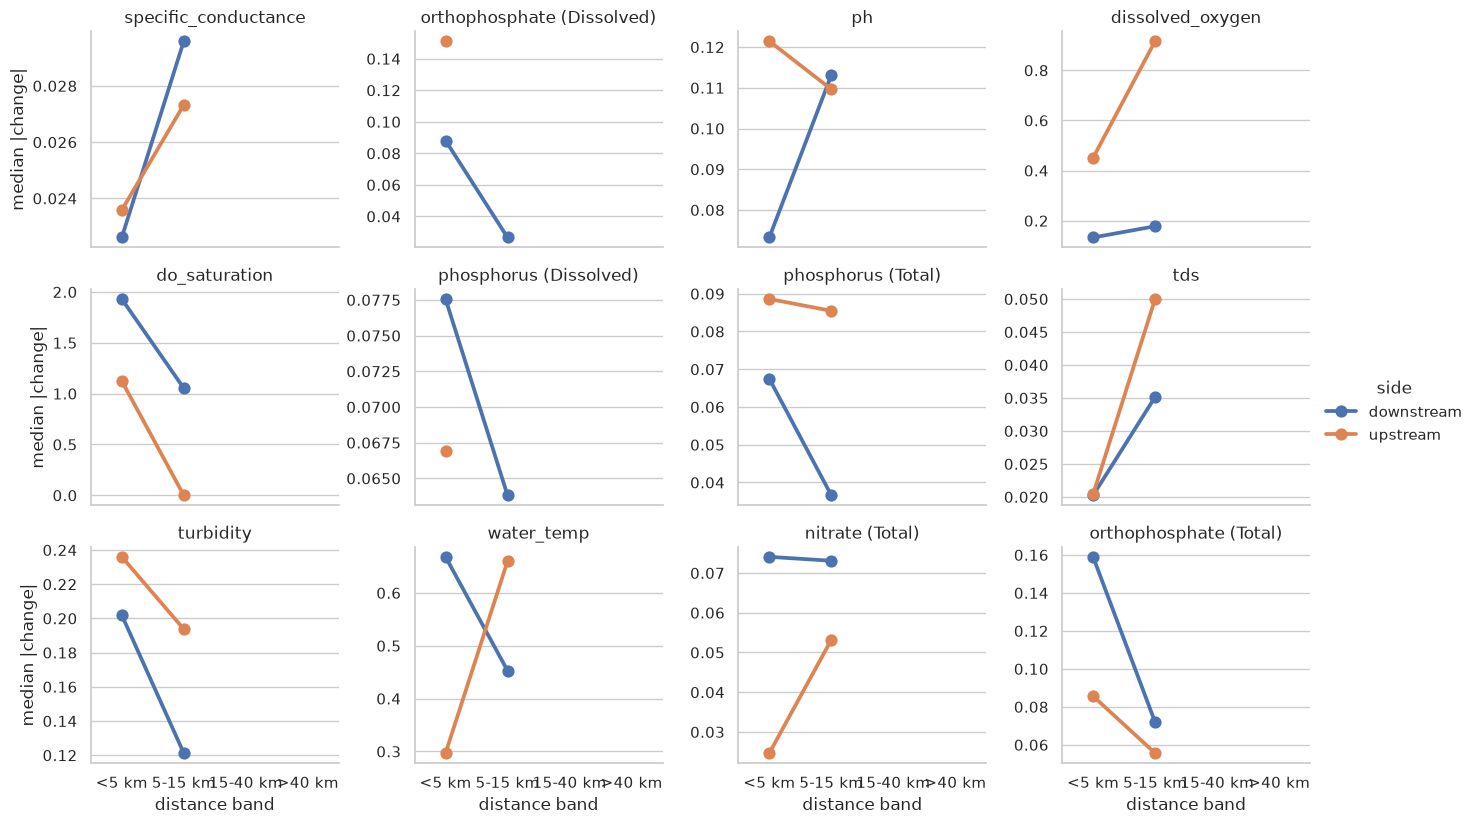

In [26]:
# Median size of change by distance band                                                                                    
bands = [0, 5, 15, 40, np.inf]                                                                                                    
labels = ["<5 km", "5-15 km", "15-40 km", ">40 km"]                                                                               
dist["distance_band"] = pd.cut(dist["network_distance_km"], bands, labels=labels, include_lowest=True)                            
                                                                                                                                
summary_bands = (dist[dist["series"].isin(MAIN)]                                                                                  
               .groupby(["series", "side", "distance_band"], observed=False)["abs_change"]                                      
               .agg(["median", "count"]).round(3))                                                                              
display(summary_bands.unstack("distance_band"))                                                                                   
                                                                                                                                
g = sns.catplot(data=dist[dist["series"].isin(MAIN)], x="distance_band", y="abs_change", hue="side",                              
              col="series", col_wrap=4, kind="point", estimator="median", errorbar=None,                                        
              hue_order=["downstream", "upstream"], sharey=False, height=2.8, aspect=1.2)                                       
g.set_titles("{col_name}")                                                                                                        
g.set_axis_labels("distance band", "median |change|")                   

distance_group,near (<= 15 km)
series,
dissolved_oxygen,90
do_saturation,40
nitrate (Total),12
orthophosphate (Dissolved),31
orthophosphate (Total),35
ph,94
phosphorus (Dissolved),22
phosphorus (Total),39
specific_conductance,96


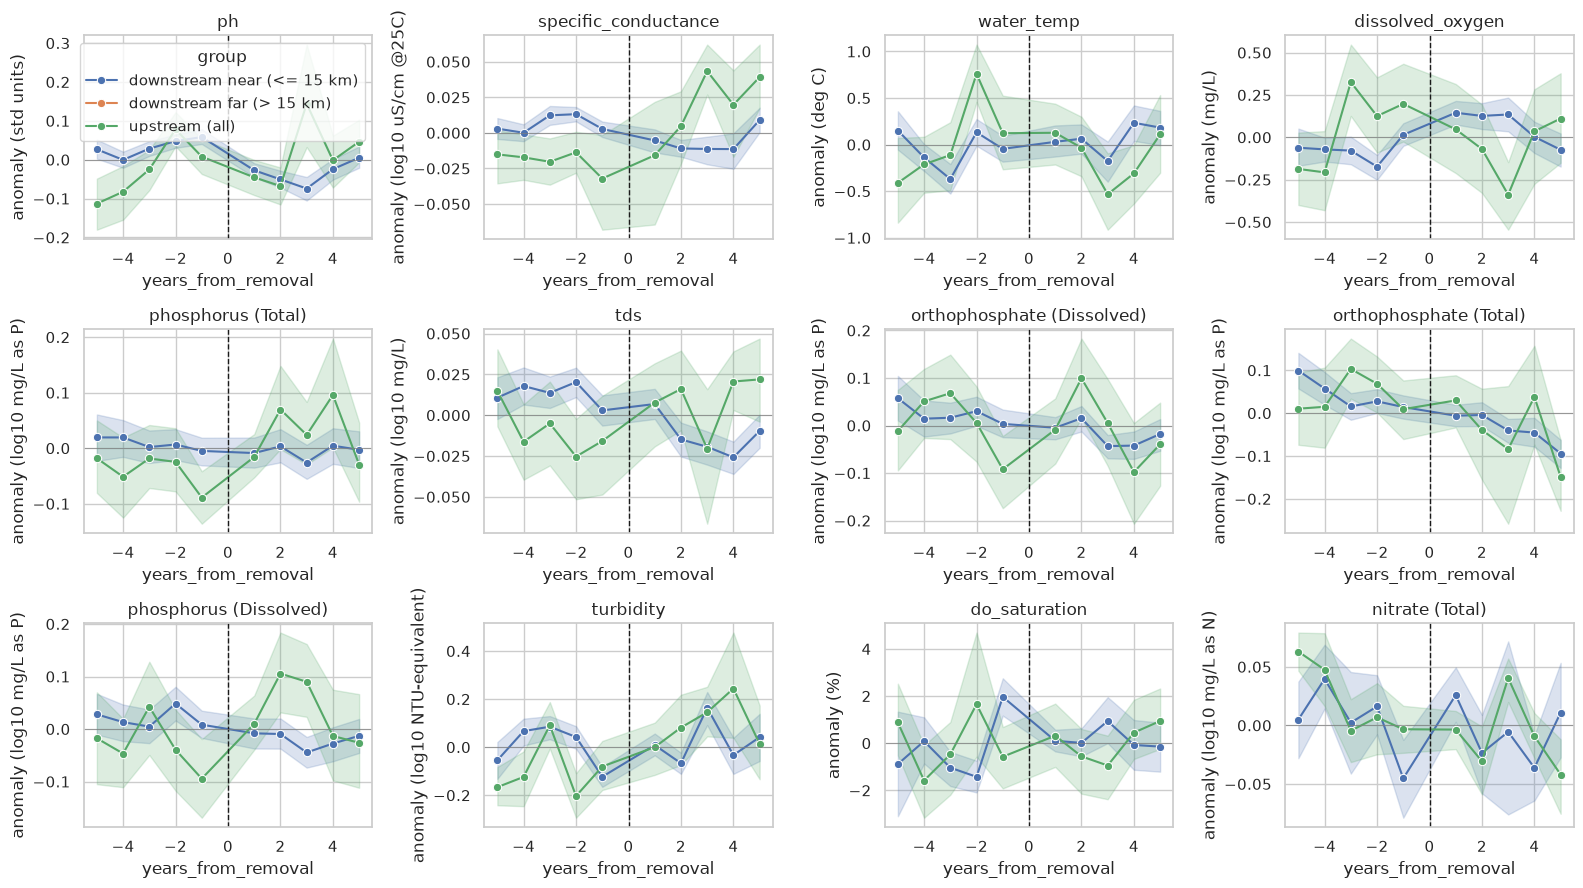

In [27]:
# Event study, near vs far downstream stations                                                                              
df["distance_group"] = np.where(df["network_distance_km"] <= NEAR_KM, f"near (<= {NEAR_KM} km)",                                  
                              f"far (> {NEAR_KM} km)")                                                                          
df["group"] = np.where(df["side"] == "downstream", "downstream " + df["distance_group"], "upstream (all)")                        
ORDER = [f"downstream near (<= {NEAR_KM} km)", f"downstream far (> {NEAR_KM} km)", "upstream (all)"]                              
                                                                                                                                
fig, axes = facet_axes(len(MAIN))                                                                                                 
for ax, series in zip(axes, MAIN):                                                                                                
  sns.lineplot(data=df[df["series"] == series], x="years_from_removal", y="anomaly", hue="group",                               
               hue_order=ORDER, errorbar=("ci", 95), marker="o", ax=ax, legend=ax is axes[0])                                   
  ax.axvline(0, color="k", ls="--", lw=1)                                                                                       
  ax.axhline(0, color="gray", lw=0.5)                                                                                           
  ax.set(title=series, ylabel=f"anomaly ({y_label(series)})")                                                                   
fig.tight_layout()

# How many pairs are near / far downstream, per series.                                                                           
(df[df["series"].isin(MAIN) & (df["side"] == "downstream")]                                                                       
 .groupby(["series", "distance_group"])["pair"].nunique().unstack(fill_value=0))                                                

In [28]:
# Models, near-only effect and distance interaction                                                                         
df["log10_dist_km"] = np.log10(df["network_distance_km"].clip(lower=0.1))                                                         
rows = []                                                                                                                         
for series in MAIN:                                                                                                               
  data = df[(df["series"] == series) & (df["side"] == "downstream")].dropna(                                                    
      subset=["air_temp_mean_c", "precip_prev_month_mm", "network_distance_km"])                                                
  near = data[data["network_distance_km"] <= NEAR_KM]                                                                           
  if near["pair"].nunique() >= 3:                                                                                               
      rows.append({"series": series, "model": f"before/after, near only (<= {NEAR_KM} km)",                                     
                   **fit(f"y ~ post + {COVARIATE_TERMS}", near, "post")})                                                       
  if data["pair"].nunique() >= 5:                                                                                               
      rows.append({"series": series, "model": "post x log10 distance (all downstream)",                                         
                   **fit(f"y ~ post * log10_dist_km + {COVARIATE_TERMS}", data, "post:log10_dist_km")})                         
distance_results = pd.DataFrame(rows)                                                                                             
distance_results.round(4)

/home/creighton.jo/.conda/envs/dam-removal/lib/python3.11/site-packages/statsmodels/base/model.py:589: SingularMatrixWarning: Random effects covariance is singular
  return -self.score(params, *args) / nobs
/home/creighton.jo/.conda/envs/dam-removal/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2429: SingularMatrixWarning: The random effects covariance matrix is singular.
  scale = self.get_scale(fe_params, cov_re_unscaled, vcomp_unscaled)
/tmp/ipykernel_2266043/1857899142.py:16: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  result = smf.mixedlm(formula, rows, groups=rows["pair"]).fit(reml=True, method="lbfgs")
/tmp/ipykernel_2266043/1857899142.py:16: SingularMatrixWarning: The random effects covariance matrix is singular.
  result = smf.mixedlm(formula, rows, groups=rows["pair"]).fit(reml=True, method="lbfgs")
/tmp/ipykernel_2266043/1857899142.py:16: ConvergenceWarning: The Hessian matrix at the estimated parameter values is n

,series,model,effect,ci_low,ci_high,p,rows,pairs
0,ph,"before/after, near only (<= 15 km)",-0.0823,-0.0979,-0.0666,0.0000,10325,94
1,ph,post x log10 distance (all downstream),-0.1667,-0.2340,-0.0995,0.0000,10325,94
2,specific_conductance,"before/after, near only (<= 15 km)",-0.0120,-0.0176,-0.0063,0.0000,10312,96
3,specific_conductance,post x log10 distance (all downstream),-0.0402,-0.0630,-0.0173,0.0006,10312,96
4,water_temp,"before/after, near only (<= 15 km)",-0.0526,-0.1845,0.0793,0.4345,7795,88
5,water_temp,post x log10 distance (all downstream),-0.0460,-0.5685,0.4764,0.8629,7795,88
6,dissolved_oxygen,"before/after, near only (<= 15 km)",0.2102,0.1490,0.2714,0.0000,6905,90
7,dissolved_oxygen,post x log10 distance (all downstream),0.2618,0.0543,0.4692,0.0134,6905,90
8,phosphorus (Total),"before/after, near only (<= 15 km)",-0.0172,-0.0386,0.0041,0.1140,3737,39
9,phosphorus (Total),post x log10 distance (all downstream),-0.0053,-0.0897,0.0790,0.9013,3737,39
